# ABIDE Dataset — Steps 1 & 2
## Acquire & Merge → Explore & Clean

**Project:** Autism Brain Imaging Data Exchange (ABIDE I)  
**Course:** Applied Statistics, PoliMi  
**Data:** Phenotypic CSV + FreeSurfer cortical thickness (Desikan–Killiany, 68 regions)

---

### Notebook Structure
1. **Step 1 — Acquire & Merge**: Load phenotypic data, parse FreeSurfer `.aparc.stats` files from S3, merge into one analysis-ready DataFrame, and save to CSV.  
2. **Step 2 — Explore & Clean**: Descriptive statistics, missing-data audit, outlier detection, and site-level visualisations.

---
## 0 · Imports & Configuration

In [161]:
import pandas as pd
import numpy as np
import requests
import time
import warnings
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from io import StringIO
from pathlib import Path

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:.3f}'.format)

# ── colour palette consistent with the ABIDE presentation ────────────────────
PALETTE = {'ASD': '#E05C2A', 'Control': '#2A7AE0'}   # orange / blue
DX_MAP  = {1: 'ASD', 2: 'Control'}                   # ABIDE encoding

print('All imports OK')

All imports OK


---
# STEP 1 — Acquire & Merge

## 1.1 · Load Phenotypic Data

The phenotypic CSV ships with ABIDE I and contains one row per subject.
We keep only the columns needed for the core research questions (RQ 1–6).

In [162]:
PHENO_FILE = 'Phenotypic_V1_0b_preprocessed1.csv'

PHENO_COLS = [
    'SUB_ID',           # unique subject identifier
    'FILE_ID',          # FreeSurfer folder name on S3
    'DX_GROUP',         # 1 = ASD, 2 = Control
    'AGE_AT_SCAN',
    'SEX',              # 1 = Male, 2 = Female
    'SITE_ID',
    'FIQ',              # Full-Scale IQ
    'VIQ',              # Verbal IQ
    'PIQ',              # Performance IQ
    'ADOS_TOTAL',       # clinical severity
    'HANDEDNESS_CATEGORY',
]

pheno_raw = pd.read_csv(PHENO_FILE)
# keep only columns present in this file
keep = [c for c in PHENO_COLS if c in pheno_raw.columns]
pheno = pheno_raw[keep].copy()

# human-readable labels
pheno['DX_LABEL'] = pheno['DX_GROUP'].map(DX_MAP)
pheno['SEX_LABEL'] = pheno['SEX'].map({1: 'Male', 2: 'Female'})

print(f'Phenotypic rows: {len(pheno):,}  |  columns retained: {len(pheno.columns)}')
pheno.head(3)

Phenotypic rows: 1,112  |  columns retained: 13


,SUB_ID,FILE_ID,DX_GROUP,AGE_AT_SCAN,SEX,SITE_ID,FIQ,VIQ,PIQ,ADOS_TOTAL,HANDEDNESS_CATEGORY,DX_LABEL,SEX_LABEL
0,50002,no_filename,1,16.770,1,PITT,103.000,116.000,89.000,12.000,Ambi,ASD,Male
1,50003,Pitt_0050003,1,24.450,1,PITT,124.000,128.000,115.000,13.000,R,ASD,Male
2,50004,Pitt_0050004,1,19.090,1,PITT,113.000,108.000,117.000,18.000,R,ASD,Male


## 1.2 · Parse FreeSurfer `.aparc.stats` Files from S3

ABIDE I FreeSurfer derivatives are hosted on the FCP-INDI Amazon S3 bucket.  
For each subject we download both hemisphere `.aparc.stats` files and extract **column 5 (MeanThickness, mm)**.

> **Tip:** If you have already run this cell once and saved `abide_thickness_raw.csv`, set `FORCE_DOWNLOAD = False` to skip the slow loop.

In [163]:
FORCE_DOWNLOAD = False          # set False after first successful run
CACHE_FILE     = 'abide_thickness_raw.csv'
S3_BASE        = (
    'https://s3.amazonaws.com/fcp-indi/data/Projects/'
    'ABIDE_Initiative/Outputs/freesurfer/5.1/{file_id}/stats/{hemi}.aparc.stats'
)
TIMEOUT        = 25   # seconds per request
SLEEP          = 0.05 # polite delay between requests


def parse_aparc(text: str, hemi: str) -> dict:
    """Parse a FreeSurfer aparc.stats text blob.
    Returns {hemi_regionname: mean_thickness} for all non-comment rows.
    Column indices (0-based): 0=StructName, 4=MeanThickness.
    """
    out = {}
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        parts = line.split()
        if len(parts) >= 5:
            region = f'{hemi}_{parts[0]}'
            try:
                out[region] = float(parts[4])
            except ValueError:
                pass
    return out


if FORCE_DOWNLOAD or not Path(CACHE_FILE).exists():

    rows, skipped = [], []

    for idx, (sub_id, file_id) in enumerate(zip(pheno['SUB_ID'], pheno['FILE_ID'])):

        # skip subjects with no FreeSurfer output (FILE_ID = 'no_filename')
        if pd.isna(file_id) or str(file_id).strip().lower() in ('no_filename', ''):
            skipped.append(sub_id)
            continue

        row = {'SUB_ID': sub_id}
        success = True

        for hemi in ('lh', 'rh'):
            url = S3_BASE.format(file_id=file_id, hemi=hemi)
            try:
                r = requests.get(url, timeout=TIMEOUT)
                if r.status_code != 200:
                    raise IOError(f'HTTP {r.status_code}')
                row.update(parse_aparc(r.text, hemi))
            except Exception as e:
                skipped.append(sub_id)
                success = False
                print(f'  [{idx+1:4d}] SKIP {file_id}  ({e})')
                break

        if success:
            rows.append(row)

        if (idx + 1) % 50 == 0:
            print(f'  {idx+1:4d} / {len(pheno)} processed  |  ok={len(rows)}  skip={len(skipped)}')

        time.sleep(SLEEP)

    thickness_raw = pd.DataFrame(rows)
    thickness_raw.to_csv(CACHE_FILE, index=False)
    print(f'\nDone — {len(rows)} subjects saved to {CACHE_FILE}  |  {len(skipped)} skipped')

else:
    thickness_raw = pd.read_csv(CACHE_FILE)
    print(f'Loaded from cache: {CACHE_FILE}  ({len(thickness_raw)} rows)')

print(f'Thickness table shape: {thickness_raw.shape}')

Loaded from cache: abide_thickness_raw.csv  (1035 rows)
Thickness table shape: (1035, 69)


## 1.3 · Merge Phenotypic + Thickness Data

In [164]:
# ── inner join on SUB_ID ────────────────────────────────────────────────────
data = pheno.merge(thickness_raw, on='SUB_ID', how='inner')

# ── identify the 68 cortical-thickness columns ──────────────────────────────
THICKNESS_COLS = [c for c in data.columns if c.startswith(('lh_', 'rh_'))]

print(f'Merged shape   : {data.shape}')
print(f'Subjects       : {len(data):,}')
print(f'ASD            : {(data["DX_LABEL"]=="ASD").sum()}')
print(f'Control        : {(data["DX_LABEL"]=="Control").sum()}')
print(f'Thickness cols : {len(THICKNESS_COLS)}')

data.to_csv('abide_merged.csv', index=False)
print('\nSaved → abide_merged.csv')

Merged shape   : (1035, 81)
Subjects       : 1,035
ASD            : 505
Control        : 530
Thickness cols : 68

Saved → abide_merged.csv


---
# STEP 2 — Explore & Clean

## 2.1 · Descriptive Statistics — Phenotypic Variables

In [165]:
# ── overall summary ──────────────────────────────────────────────────────────
pheno_summary_cols = ['AGE_AT_SCAN', 'FIQ', 'VIQ', 'PIQ', 'ADOS_TOTAL']
pheno_summary_cols = [c for c in pheno_summary_cols if c in data.columns]

summary = data.groupby('DX_LABEL')[pheno_summary_cols].agg(['mean', 'std', 'median'])
print('=== Group-level descriptives ===')
print(summary.round(2).to_string())
print(data.shape)

=== Group-level descriptives ===
         AGE_AT_SCAN                   FIQ                       VIQ                       PIQ                  ADOS_TOTAL                
                mean   std median     mean      std  median     mean      std  median     mean      std  median       mean      std median
DX_LABEL                                                                                                                                  
ASD           17.100 8.550 14.420 -245.090 1851.120 104.000   33.500  843.080 103.000   11.690  969.040 106.000   -424.650 2046.960 11.000
Control       16.810 7.450 14.660 -245.130 1865.630 110.000 -229.320 1826.800 111.000 -287.570 1961.960 108.000  -1998.880 4082.540  1.000
(1035, 81)


In [166]:
# ── sex distribution by diagnosis ───────────────────────────────────────────
sex_table = pd.crosstab(data['DX_LABEL'], data['SEX_LABEL'], margins=True)
print('=== Sex × Diagnosis ===')
print(sex_table)

=== Sex × Diagnosis ===
SEX_LABEL  Female  Male   All
DX_LABEL                     
ASD            62   443   505
Control        95   435   530
All           157   878  1035


In [167]:
# ── subjects per site ────────────────────────────────────────────────────────
site_counts = (
    data.groupby(['SITE_ID', 'DX_LABEL'])
    .size()
    .unstack(fill_value=0)
    .assign(Total=lambda d: d.sum(axis=1))
    .sort_values('Total', ascending=False)
)
print('=== Subjects per Site ===')
print(site_counts)

=== Subjects per Site ===
DX_LABEL  ASD  Control  Total
SITE_ID                      
NYU        75      100    175
UM_1       53       53    106
UCLA_1     41       31     72
USM        46       25     71
YALE       28       28     56
PITT       29       27     56
MAX_MUN    24       28     52
KKI        20       28     48
TRINITY    22       25     47
STANFORD   19       20     39
CALTECH    19       18     37
SDSU       14       22     36
OLIN       19       15     34
LEUVEN_2   15       19     34
UM_2       13       21     34
SBL        15       15     30
LEUVEN_1   14       15     29
CMU        14       13     27
OHSU       12       14     26
UCLA_2     13       13     26


## 2.2 · Missing-Data Audit

In [168]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate missing data for ALL columns in the dataset
total_miss = data.isnull().sum()
pct_miss = (total_miss / len(data)) * 100

# 2. Combine into a clean DataFrame
missing_df = pd.DataFrame({'Total Missing': total_miss, 'Percentage (%)': pct_miss})

# 3. Filter to ONLY show columns that are actually missing data, and sort worst-to-best
missing_df = missing_df[missing_df['Total Missing'] > 0].sort_values(by='Percentage (%)', ascending=False)

print('=== Comprehensive Missing Data Report ===')
# Using .to_string() makes the pandas printout look much cleaner in the console
print(missing_df.round(2).to_string())
print(f'\nTotal columns with missing data: {len(missing_df)}')


=== Comprehensive Missing Data Report ===
                             Total Missing  Percentage (%)
ADOS_TOTAL                             643          62.130
HANDEDNESS_CATEGORY                    276          26.670
VIQ                                    161          15.560
PIQ                                    143          13.820
FIQ                                     34           3.290
rh_posteriorcingulate                    2           0.190
rh_entorhinal                            1           0.100
rh_temporalpole                          1           0.100
rh_rostralanteriorcingulate              1           0.100
rh_pericalcarine                         1           0.100
rh_parahippocampal                       1           0.100
rh_fusiform                              1           0.100
rh_caudalanteriorcingulate               1           0.100
rh_cuneus                                1           0.100
lh_transversetemporal                    1           0.100
lh_rostralante

In [169]:
# The specific columns you suspect are tied to the same patient(s)
suspicious_cols = [
    'rh_posteriorcingulate', 'rh_entorhinal', 'rh_temporalpole',
    'rh_rostralanteriorcingulate', 'rh_pericalcarine', 'rh_parahippocampal',
    'rh_fusiform', 'rh_caudalanteriorcingulate', 'rh_cuneus',
    'lh_transversetemporal', 'lh_rostralanteriorcingulate',
    'lh_medialorbitofrontal', 'lh_isthmuscingulate',
    'lh_caudalanteriorcingulate', 'rh_transversetemporal'
]

# Filter the dataframe to only show rows where ANY of these columns are NaN
missing_rows = data[data[suspicious_cols].isna().any(axis=1)]

# To make it readable, let's just look at the Subject ID, Site, and these specific columns
cols_to_show = ['SUB_ID', 'SITE_ID'] + suspicious_cols

# Transpose it (.T) so it prints vertically, which is much easier to read in Jupyter
print("=== Subjects Missing Specific Cortical Regions ===")
print(missing_rows[cols_to_show].T)

=== Subjects Missing Specific Cortical Regions ===
                               188    190    193    199    204    241  \
SUB_ID                       50272  50274  50277  50283  50288  50327   
SITE_ID                       UM_1   UM_1   UM_1   UM_1   UM_1   UM_1   
rh_posteriorcingulate        2.088    NaN  2.769  1.899    NaN  1.455   
rh_entorhinal                2.221  1.886  2.167  2.372  1.840    NaN   
rh_temporalpole              3.263  2.040  2.076  3.024  2.582    NaN   
rh_rostralanteriorcingulate  2.336  1.517  3.095  2.084    NaN  2.631   
rh_pericalcarine             2.032  3.042  2.186    NaN  1.901  2.487   
rh_parahippocampal           2.373  1.854  2.168  2.774  2.492  1.551   
rh_fusiform                  2.243  2.037  2.091  2.797  2.727    NaN   
rh_caudalanteriorcingulate   2.166  2.211  2.035  1.929    NaN  2.690   
rh_cuneus                    2.361  2.569  2.706    NaN  2.599  3.282   
lh_transversetemporal        2.272  1.951    NaN  1.702  2.781  3.231   


In [170]:
# 1. Define the 68 brain regions
thickness_cols = [c for c in data.columns if c.startswith('lh_') or c.startswith('rh_')]

# 2. DROP subjects missing any cortical thickness data
df_clean = data.dropna(subset=thickness_cols).copy()

print(f"Original subjects: {len(data)}")
print(f"Subjects remaining after dropping missing brains: {len(df_clean)}\n")

# 3. IMPUTE missing IQ scores with the site-specific median
iq_cols = ['FIQ', 'VIQ', 'PIQ']

for col in iq_cols:
    if col in df_clean.columns:
        # Fill missing IQs with the median of that specific hospital/site
        df_clean[col] = df_clean.groupby('SITE_ID')[col].transform(lambda x: x.fillna(x.median()))

# 4. Final check!
remaining_miss = df_clean[thickness_cols + iq_cols].isna().sum().sum()
print(f"Total missing values in brain regions + IQ columns: {remaining_miss}")

Original subjects: 1035
Subjects remaining after dropping missing brains: 1027

Total missing values in brain regions + IQ columns: 302


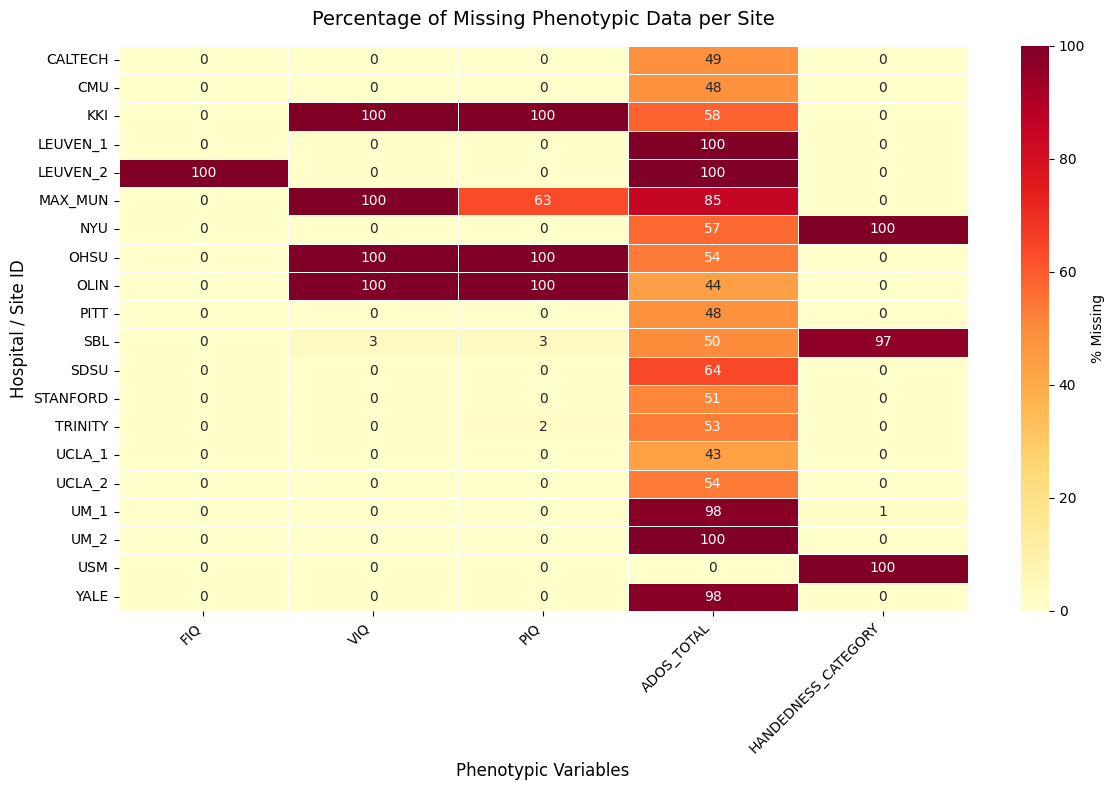

In [171]:

# 1. Define the key phenotypic columns you want to audit
audit_cols = [
     'FIQ', 'VIQ', 'PIQ', 
    'ADOS_TOTAL', 'HANDEDNESS_CATEGORY'
]

# Safety check: Only keep columns that actually exist in your dataframe
audit_cols = [c for c in audit_cols if c in data.columns]

# 2. Calculate the percentage of missing data per site
# This groups by site, checks for NaNs, calculates the mean (which gives the decimal percentage), and multiplies by 100
site_miss = (
    data.groupby('SITE_ID')[audit_cols]
    .apply(lambda d: d.isna().mean() * 100)
)

# 3. Create the Heatmap
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(
    site_miss, 
    annot=True,     # Show the actual percentage numbers inside the boxes
    fmt='.0f',      # Format as whole numbers (e.g., '62' instead of '62.14')
    cmap='YlOrRd',  # Yellow -> Orange -> Red (Red = heavily missing)
    linewidths=0.4, 
    ax=ax, 
    cbar_kws={'label': '% Missing'}
)

# 4. Clean up the titles and labels
ax.set_title('Percentage of Missing Phenotypic Data per Site', fontsize=14, pad=15)
ax.set_xlabel('Phenotypic Variables', fontsize=12)
ax.set_ylabel('Hospital / Site ID', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# Save it if you want to keep it for your presentation!
# plt.savefig('fig_missing_heatmap_by_site.png', dpi=150)

plt.show()

## 2.3 · Outlier Detection

We flag subjects whose **mean cortical thickness** (averaged across all 68 regions) falls more than 3 standard deviations from the overall mean.

In [172]:
# ── per-subject mean thickness ───────────────────────────────────────────────
data['mean_thickness'] = data[THICKNESS_COLS].mean(axis=1)

mu  = data['mean_thickness'].mean()
sig = data['mean_thickness'].std()
z   = (data['mean_thickness'] - mu) / sig
data['thick_z'] = z

outliers = data[z.abs() > 3]
print(f'Global mean thickness : {mu:.3f} mm  (SD={sig:.3f})')
print(f'Outliers (|z|>3)      : {len(outliers)} subjects')
if len(outliers):
    print(outliers[['SUB_ID', 'SITE_ID', 'DX_LABEL', 'mean_thickness', 'thick_z']].to_string())

Global mean thickness : 2.755 mm  (SD=0.199)
Outliers (|z|>3)      : 0 subjects


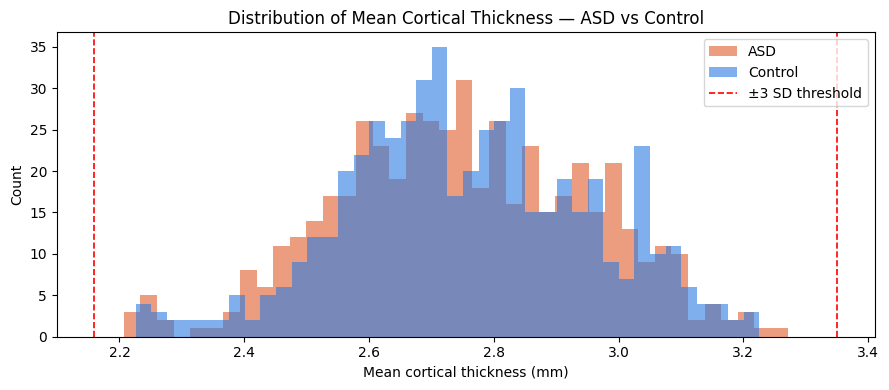

In [173]:
# ── distribution of mean thickness with outlier markers ─────────────────────
fig, ax = plt.subplots(figsize=(9, 4))
for dx, grp in data.groupby('DX_LABEL'):
    ax.hist(grp['mean_thickness'], bins=40, alpha=0.6,
            color=PALETTE[dx], label=dx, edgecolor='none')
ax.axvline(mu - 3*sig, color='red', ls='--', lw=1.2, label='±3 SD threshold')
ax.axvline(mu + 3*sig, color='red', ls='--', lw=1.2)
ax.set_xlabel('Mean cortical thickness (mm)')
ax.set_ylabel('Count')
ax.set_title('Distribution of Mean Cortical Thickness — ASD vs Control')
ax.legend()
plt.tight_layout()
plt.savefig('fig_thickness_distribution.png', dpi=150)
plt.show()

In [174]:
# 1. Isolate the 68 brain region columns
thickness_cols = [c for c in df_clean.columns if c.startswith('lh_') or c.startswith('rh_')]

# 2. Calculate Q1, Q3, and the IQR for every column
Q1 = df_clean[thickness_cols].quantile(0.25)
Q3 = df_clean[thickness_cols].quantile(0.75)
IQR = Q3 - Q1

# Define the acceptable bounds (1.5 * IQR is standard)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 3. Count the outliers per region
outlier_mask = (df_clean[thickness_cols] < lower_bound) | (df_clean[thickness_cols] > upper_bound)
outlier_counts = outlier_mask.sum().sort_values(ascending=False)

print("=== Top 10 Regions with the Most Outliers ===")
print(outlier_counts.head(10))

=== Top 10 Regions with the Most Outliers ===
rh_temporalpole               36
lh_temporalpole               28
lh_middletemporal             26
lh_lateraloccipital           24
lh_bankssts                   21
rh_middletemporal             20
rh_entorhinal                 19
rh_pericalcarine              18
lh_superiortemporal           17
lh_caudalanteriorcingulate    16
dtype: int64


In [175]:
# 1. Define our hard biological limits
# Normal is ~1.5 to 4.5. We leave a buffer for atypical brains (e.g., 1.2 or 4.8).
LOWER_BIOLOGICAL_LIMIT = 1.0
UPPER_BIOLOGICAL_LIMIT = 5.0

# 2. Create a mask that flags ONLY the biologically impossible values
# thickness_cols should still be your list of the 68 regions
impossible_mask = (df_clean[thickness_cols] < LOWER_BIOLOGICAL_LIMIT) | \
                  (df_clean[thickness_cols] > UPPER_BIOLOGICAL_LIMIT)

# 3. Let's see how many of these processing errors exist
impossible_counts = impossible_mask.sum().sort_values(ascending=False)
impossible_counts = impossible_counts[impossible_counts > 0]

print("=== Regions with Biologically Impossible Values ===")
if len(impossible_counts) > 0:
    print(impossible_counts)
else:
    print("Good news: No biologically impossible values found!")

# 4. Find out how many subjects are affected
bad_scans = df_clean[impossible_mask.any(axis=1)]
print(f"\nNumber of subjects with botched FreeSurfer scans: {len(bad_scans)}")

# 5. Drop these specific subjects
# If the software failed this badly on a region, we can't trust the rest of their scan
df_clean = df_clean[~impossible_mask.any(axis=1)].copy()
print(f"Final clean dataset size: {len(df_clean)} subjects")

=== Regions with Biologically Impossible Values ===
Good news: No biologically impossible values found!

Number of subjects with botched FreeSurfer scans: 0
Final clean dataset size: 1027 subjects


## 2.4 · Site-Level Distributions

Site effects are a central concern in ABIDE (RQ 1). Here we visualise how mean cortical thickness varies across the 17 acquisition sites.

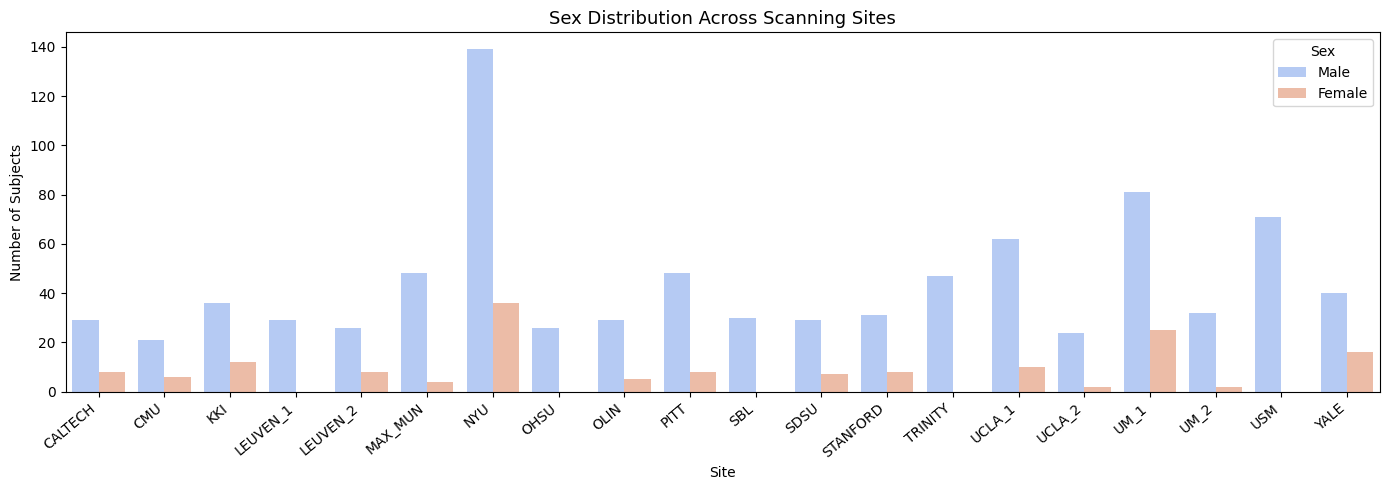

In [176]:
import matplotlib.pyplot as plt
import seaborn as sns
my_df=data
# Assuming your cleaned dataframe is still called my_df
# We use 'SEX_LABEL' so the legend says "Male/Female" instead of just "1/2"

# 1. Get the alphabetical site order
site_order = sorted(my_df['SITE_ID'].dropna().unique())

# 2. Create the Count Plot
fig, ax = plt.subplots(figsize=(14, 5))
sns.countplot(
    data=my_df, 
    x='SITE_ID', 
    hue='SEX_LABEL', 
    palette='coolwarm', # A contrasting palette for two categories
    order=site_order,
    ax=ax
)

# 3. Add titles and layout
ax.set_title('Sex Distribution Across Scanning Sites', fontsize=13)
ax.set_xlabel('Site')
ax.set_ylabel('Number of Subjects')
plt.xticks(rotation=40, ha='right')
ax.legend(title='Sex', loc='upper right')
plt.tight_layout()

# 4. Show the plot
plt.show()

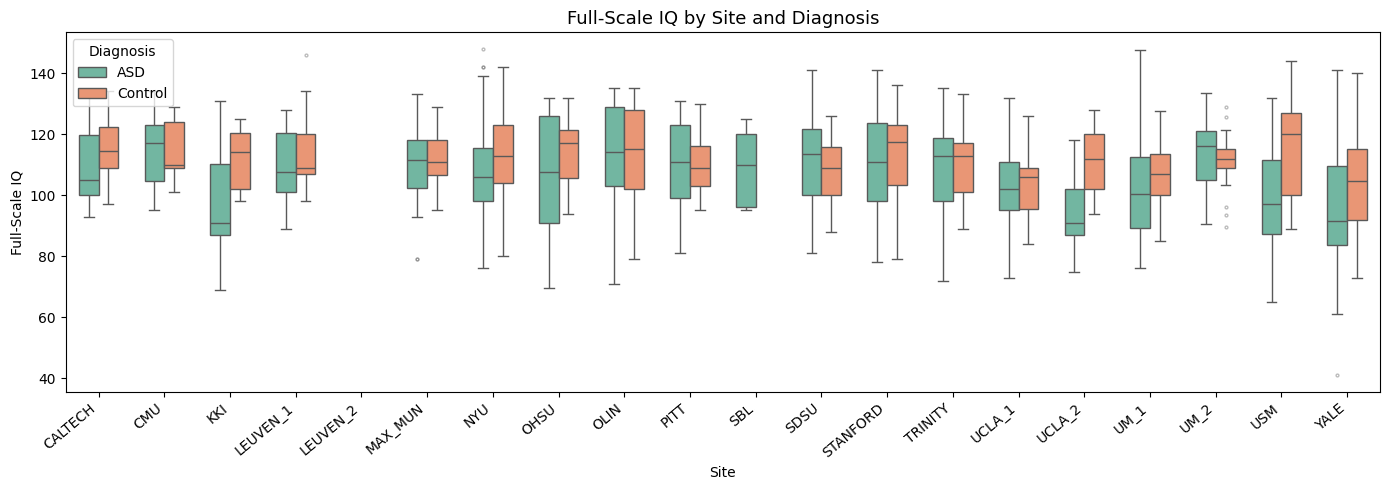

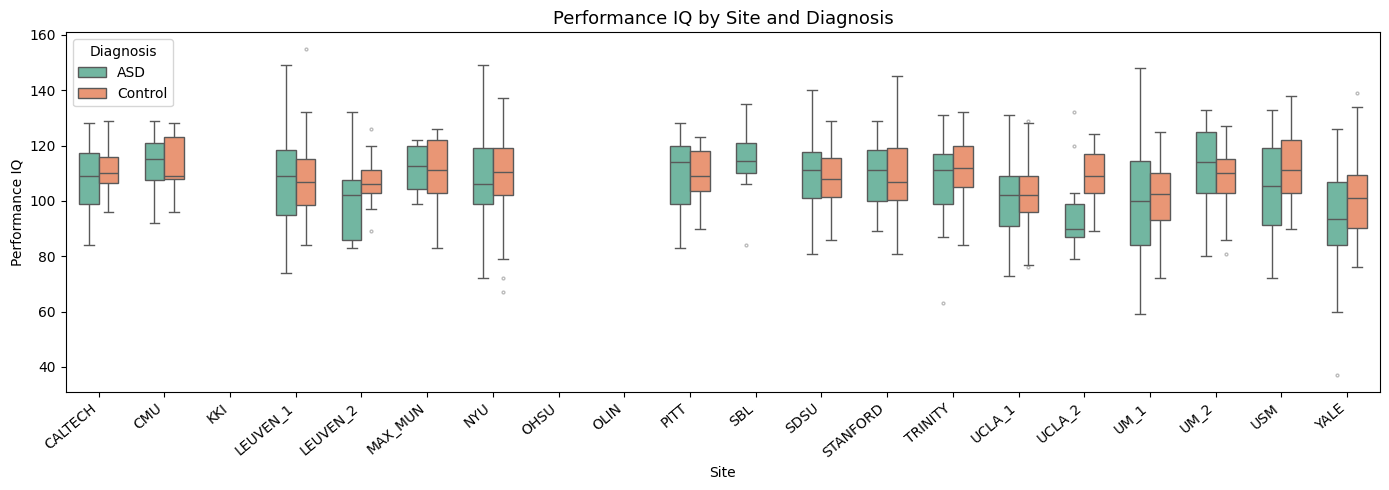

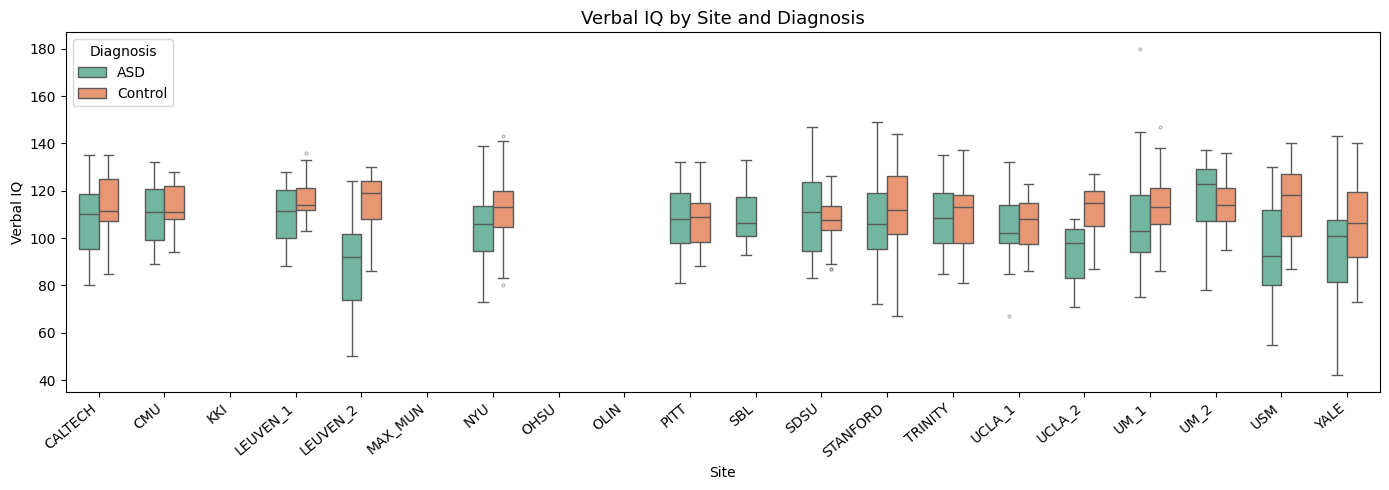

In [177]:

import matplotlib.pyplot as plt
import seaborn as sns

# Let's map this to the dataframe you actually have in memory. 
# Change this to df_clean if 'data' isn't your variable name!
my_df = data 
# Replace all instances of -9999 with NaN
my_df = my_df.replace({-9999: np.nan, '-9999': np.nan})

# You might also want to check for -9999.0 just in case it's a float
my_df = my_df.replace(-9999.0, np.nan)
pheno_vars = [
    ('FIQ', 'Full-Scale IQ'),
    ('PIQ', 'Performance IQ'),
    ('VIQ', 'Verbal IQ'),


]

for var, label in pheno_vars:
    
    # Safety check: does the column exist?
    if var not in my_df.columns:
        print(f" ERROR: Column '{var}' not found in dataframe!")
        continue
        
    try:
        # 1. Calculate site order (ignoring NaNs to prevent sorting errors)
        site_order = sorted(my_df['SITE_ID'].dropna().unique())

        # 2. Create the plot using a hardcoded palette to avoid NameErrors
        fig, ax = plt.subplots(figsize=(14, 5))
        sns.boxplot(
            data=my_df, x='SITE_ID', y=var, hue='DX_LABEL',
            palette='Set2',
            order=site_order, width=0.6,
            flierprops=dict(marker='o', markersize=2, alpha=0.4), ax=ax
        )
        
        # 3. Add titles and layout
        ax.set_title(f'{label} by Site and Diagnosis', fontsize=13)
        ax.set_xlabel('Site')
        ax.set_ylabel(label)
        plt.xticks(rotation=40, ha='right')
        ax.legend(title='Diagnosis', loc='upper left')
        plt.tight_layout()
        
        # 4. Show the plot!
        plt.show() 
    
        
    except Exception as e:
        print(f" Failed to plot {var}. Error: {e}\n")

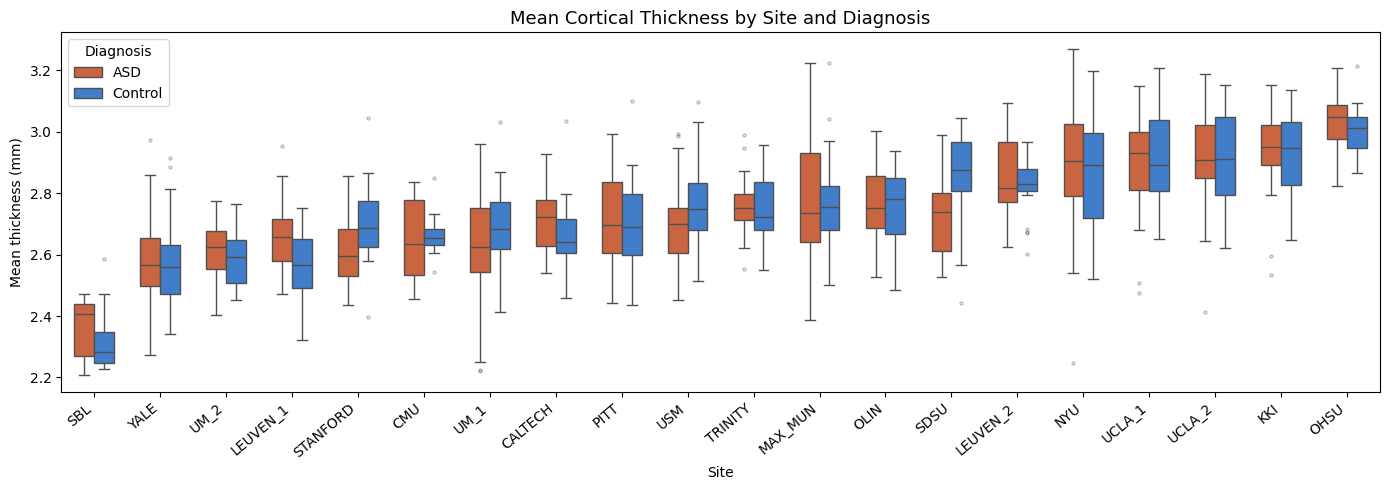

In [178]:
# ── boxplot: mean thickness by site, coloured by diagnosis ──────────────────
site_order = (
    data.groupby('SITE_ID')['mean_thickness']
    .median()
    .sort_values()
    .index.tolist()
)
#site_order = sorted(my_df['SITE_ID'].dropna().unique())
fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(
    data=data, x='SITE_ID', y='mean_thickness', hue='DX_LABEL',
    palette=PALETTE, order=site_order, width=0.6,
    flierprops=dict(marker='o', markersize=2, alpha=0.4), ax=ax
)
ax.set_title('Mean Cortical Thickness by Site and Diagnosis', fontsize=13)
ax.set_xlabel('Site')
ax.set_ylabel('Mean thickness (mm)')
plt.xticks(rotation=40, ha='right')
ax.legend(title='Diagnosis', loc='upper left')
plt.tight_layout()
plt.savefig('fig_site_boxplot.png', dpi=150)
plt.show()

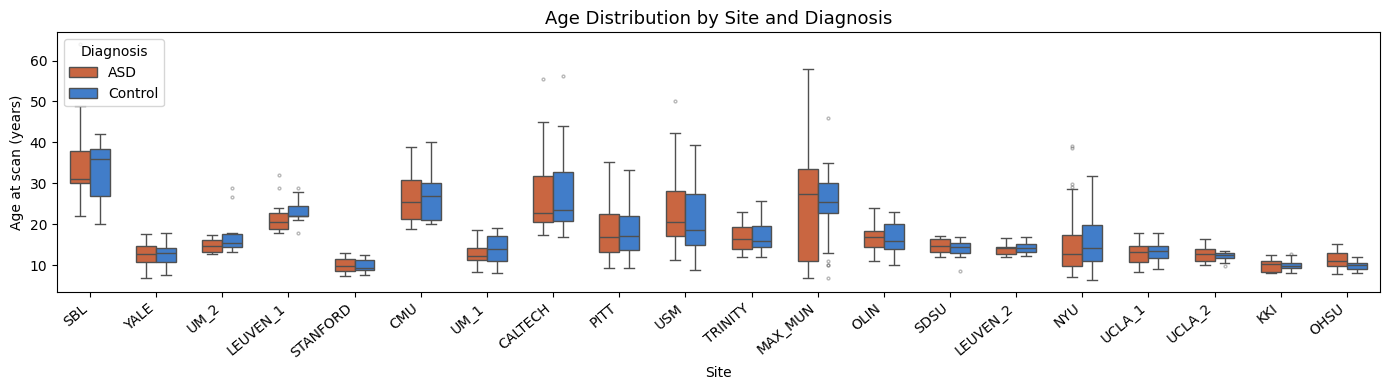

In [179]:
# ── age distribution by site ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 4))
sns.boxplot(
    data=data, x='SITE_ID', y='AGE_AT_SCAN', hue='DX_LABEL',
    palette=PALETTE, order=site_order, width=0.6,
    flierprops=dict(marker='o', markersize=2, alpha=0.4), ax=ax
)
ax.set_title('Age Distribution by Site and Diagnosis', fontsize=13)
ax.set_xlabel('Site')
ax.set_ylabel('Age at scan (years)')
plt.xticks(rotation=40, ha='right')
ax.legend(title='Diagnosis', loc='upper left')
plt.tight_layout()
plt.savefig('fig_site_age_boxplot.png', dpi=150)
plt.show()

SBL site works with adults not children having fairly lower cortical thickness values 

## 2.5 · Correlation Structure of the 68-Region Thickness Profile

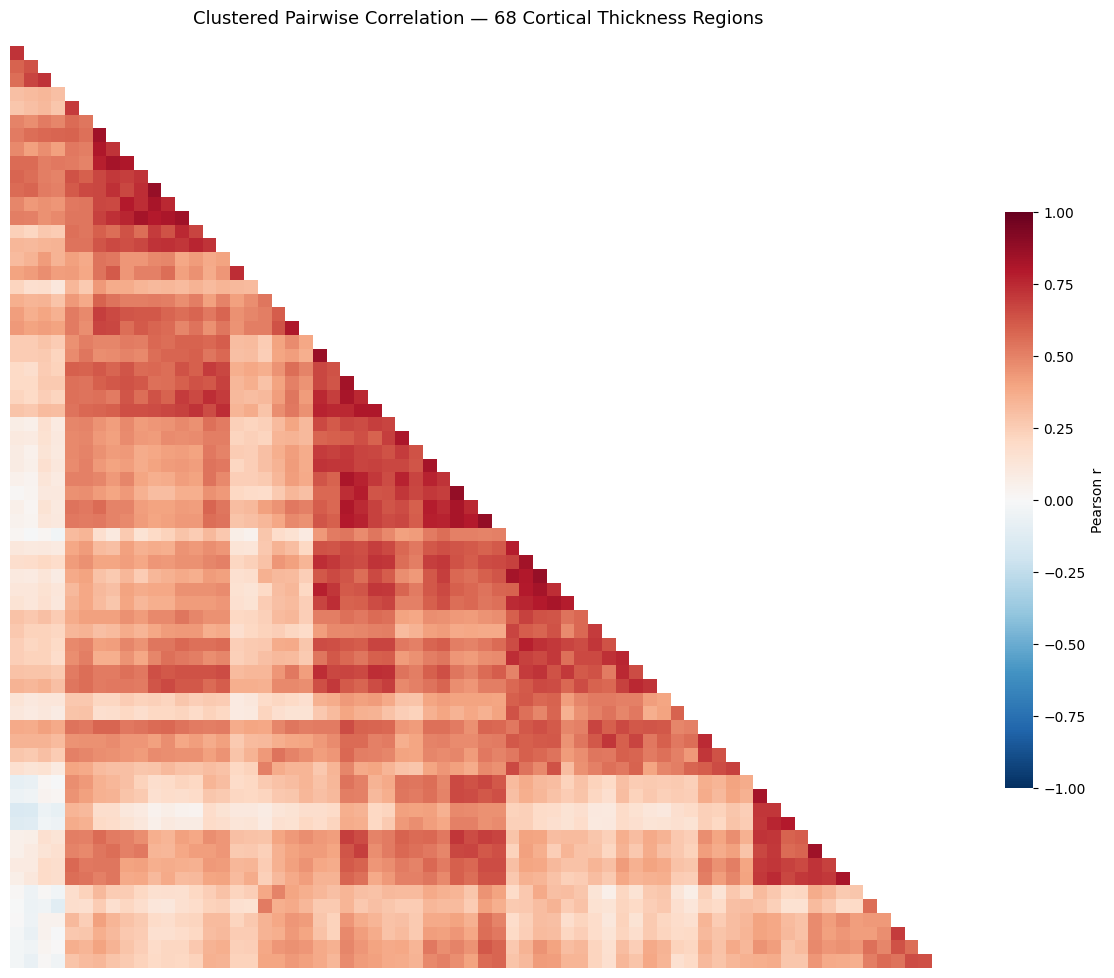


Region pairs with r > 0.80: 32
           region_A                region_B     r
rh_superiorparietal     lh_superiorparietal 0.881
       rh_precuneus            lh_precuneus 0.880
 rh_superiorfrontal      lh_superiorfrontal 0.875
rh_superiortemporal     lh_superiortemporal 0.869
      rh_precentral           lh_precentral 0.865
  rh_middletemporal       lh_middletemporal 0.850
rh_lateraloccipital     lh_lateraloccipital 0.847
        rh_fusiform             lh_fusiform 0.846
rh_inferiorparietal     lh_inferiorparietal 0.840
 lh_superiorfrontal lh_rostralmiddlefrontal 0.840


In [180]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.cluster.hierarchy as sch
import scipy.spatial.distance as ssd

# 1. Calculate the raw correlation matrix
corr_raw = data[THICKNESS_COLS].corr()

# 2. Convert correlations to distances (1 - correlation) 
# Regions with high correlation will have a distance near 0
distances = 1 - corr_raw.abs()
dist_array = ssd.squareform(distances)

# 3. Perform hierarchical clustering to find the optimal sorting order
linkage = sch.linkage(dist_array, method='ward')
dendro = sch.dendrogram(linkage, no_plot=True)
sorted_indices = dendro['leaves']
sorted_cols = corr_raw.columns[sorted_indices]

# 4. Reorder the correlation matrix based on the clustering
corr_sorted = corr_raw.loc[sorted_cols, sorted_cols]

# 5. Plot using your original excellent styling!
fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_sorted, dtype=bool))   # upper-triangle mask

sns.heatmap(
    corr_sorted, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    square=True, linewidths=0, ax=ax,
    xticklabels=False, yticklabels=False,
    cbar_kws={'label': 'Pearson r', 'shrink': 0.6}
)
ax.set_title('Clustered Pairwise Correlation — 68 Cortical Thickness Regions', fontsize=13)
plt.tight_layout()
plt.savefig('fig_correlation_heatmap_clustered.png', dpi=150)
plt.show()

# 6. Report high-correlation pairs (using the sorted matrix so it matches the visual)
upper = corr_sorted.where(mask == False)
np.fill_diagonal(upper.values, np.nan)
high = (
    upper.stack()
    .reset_index()
    .rename(columns={'level_0': 'region_A', 'level_1': 'region_B', 0: 'r'})
    .query('r > 0.8')
    .sort_values('r', ascending=False)
)
print(f'\nRegion pairs with r > 0.80: {len(high)}')
print(high.head(10).to_string(index=False))

In [181]:
# 1. Drop the 8 subjects missing cortical thickness data
# We check a known thickness column, or drop any row with NaNs in thickness columns
thickness_cols = [col for col in data.columns if col.startswith('lh_') or col.startswith('rh_')]
df_clean = data.dropna(subset=thickness_cols).copy()
print(f"Shape after dropping missing thickness: {df_clean.shape}")

# 2. Descriptive statistics for Phenotypic data
pheno_cols = ['FIQ', 'VIQ', 'PIQ', 'ADOS_TOTAL', 'AGE_AT_SCAN']
print("\n--- Descriptive Statistics ---")
print(df_clean[pheno_cols].describe())

# 3. Handling missing phenotypic data
# For IQ scores (~3-15% missing), median imputation is a common baseline approach
for col in ['FIQ', 'VIQ', 'PIQ']:
    median_val = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_val)

Shape after dropping missing thickness: (1027, 83)

--- Descriptive Statistics ---
            FIQ       VIQ       PIQ  ADOS_TOTAL  AGE_AT_SCAN
count   993.000   866.000   884.000     390.000     1027.000
mean   -247.923  -102.144  -144.919    -502.149       16.987
std    1864.817  1442.824  1575.214    2210.813        8.021
min   -9999.000 -9999.000 -9999.000   -9999.000        6.470
25%      97.500    97.000    96.000       8.000       11.627
50%     108.000   108.000   107.000      11.000       14.570
75%     119.000   119.000   117.000      14.000       20.000
max     148.000   180.000   155.000      22.000       64.000


In [182]:
pip install neuroCombat

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


## 2.7 · Stratified Train/Test Split

The ABIDE I dataset is characterised by a **strong sex imbalance** — males vastly outnumber females in both the ASD and Control groups. If we split the data randomly, certain diagnosis × sex subgroups (e.g. `ASD_Female`, `Control_Female`) could end up severely under-represented in either the training or test set, which would:

1. **Bias models** trained on the data — the classifier might never learn from rare subgroups.
2. **Invalidate evaluation metrics** — performance on the test set would not reflect real-world diversity.

To mitigate this, we create a **composite stratification label** that combines `DX_LABEL` and `SEX_LABEL` (e.g. `ASD_Male`, `Control_Female`) and pass it to `train_test_split` via the `stratify` parameter. This guarantees that every subgroup is represented in both splits in roughly the same proportions as the full dataset.

In [183]:
from sklearn.model_selection import train_test_split

# 1. Create composite stratification label
df_clean['strat_label'] = (
    df_clean['DX_LABEL'].astype(str) + '_' +
    df_clean['SEX_LABEL'].astype(str)
)

# 2. Stratified train/test split (80/20)
train_df, test_df = train_test_split(
    df_clean,
    test_size=0.2,
    random_state=42,
    stratify=df_clean['strat_label'],
)

# 3. Verify proportions are balanced
print('=== train_df strat_label proportions ===')
print(train_df['strat_label'].value_counts(normalize=True).sort_index())
print()
print('=== test_df  strat_label proportions ===')
print(test_df['strat_label'].value_counts(normalize=True).sort_index())
print()
print(f'train_df shape: {train_df.shape}')
print(f'test_df  shape: {test_df.shape}')

=== train_df strat_label proportions ===
strat_label
ASD_Female       0.061
ASD_Male         0.425
Control_Female   0.093
Control_Male     0.421
Name: proportion, dtype: float64

=== test_df  strat_label proportions ===
strat_label
ASD_Female       0.058
ASD_Male         0.427
Control_Female   0.092
Control_Male     0.422
Name: proportion, dtype: float64

train_df shape: (821, 84)
test_df  shape: (206, 84)


In [184]:
from neuroCombat import neuroCombat, neuroCombatFromTraining
import numpy as np

# ── helper: build the covariates dataframe ComBat expects ──────────────
def _make_covars(df):
    covars = df[['SITE_ID', 'DX_LABEL', 'AGE_AT_SCAN', 'SEX_LABEL']].copy()
    covars['DX_LABEL']  = covars['DX_LABEL'].map({'ASD': 1, 'Control': 0})
    covars['SEX_LABEL'] = covars['SEX_LABEL'].map({'Male': 1, 'Female': 0})
    return covars

# ── 1. FIT ComBat on the TRAINING set only ───────────────────────────
train_brain = train_df[THICKNESS_COLS].T          # features × samples
train_covars = _make_covars(train_df)

combat_result = neuroCombat(
    dat=train_brain,
    covars=train_covars,
    batch_col='SITE_ID',
    categorical_cols=['DX_LABEL', 'SEX_LABEL'],
    continuous_cols=['AGE_AT_SCAN'],
)

# Build train_harmonised from the fitted result
train_harmonised = train_df.copy()
train_harmonised[THICKNESS_COLS] = combat_result['data'].T

# ── 2. APPLY the learned parameters to the TEST set ──────────────────
test_brain  = test_df[THICKNESS_COLS].T
test_batch  = np.array(test_df['SITE_ID'])

test_combat = neuroCombatFromTraining(
    dat=test_brain,
    batch=test_batch,
    estimates=combat_result['estimates'],
)

test_harmonised = test_df.copy()
test_harmonised[THICKNESS_COLS] = test_combat['data'].T

# ── 3. Confirm no data was lost ──────────────────────────────────────
print(f'train_harmonised shape: {train_harmonised.shape}')
print(f'test_harmonised  shape: {test_harmonised.shape}')
print()
print('ComBat fitted on train_df only; parameters applied to test_df.')
print('Scanner effects removed without data leakage.')

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
[neuroCombatFromTraining] In development ...

train_harmonised shape: (821, 84)
test_harmonised  shape: (206, 84)

ComBat fitted on train_df only; parameters applied to test_df.
Scanner effects removed without data leakage.


ComBat a strict set of rules:

Find the Age Effect: "Look at the ages. Mathematically calculate how much the brain naturally thins out for every year older a patient gets."

Lock it in a Safe Box: "Take that natural age difference, take the autism difference, and take the male/female difference, and lock them in a mathematical safe box. Do not touch them."

Harmonise the Garbage: "Now, look at whatever variance is left over. That leftover variance is the scanner noise. Erase that, and then give me back my protected biological data."

combining data from 16 international institutions creates massive heterogeneity due to different MRI scanners, head coils, and acquisition parameters.ComBat (Combatting Batch Effects) assumes that every brain scan is a combination of true biology and annoying scanner errors. It looks for two specific types of scanner errors:

The "Shift" (Additive Error): Let's say the Siemens scanner at Hospital A is miscalibrated and always measures the entire brain as 0.2 mm thicker than it really is. ComBat finds this pattern and subtracts 0.2 mm from every patient at Hospital A.

The "Stretch" (Multiplicative Error): Let's say the Philips scanner at Hospital B is really noisy, meaning its measurements are way more spread out (higher variance) than the other hospitals. ComBat mathematically "squeezes" Hospital B's data so its spread matches the global average.

The Result of ComBat: Site A, Site B, and Site C now all look like they were scanned on the exact same, perfect, universal MRI machine. The scanner noise is gone.

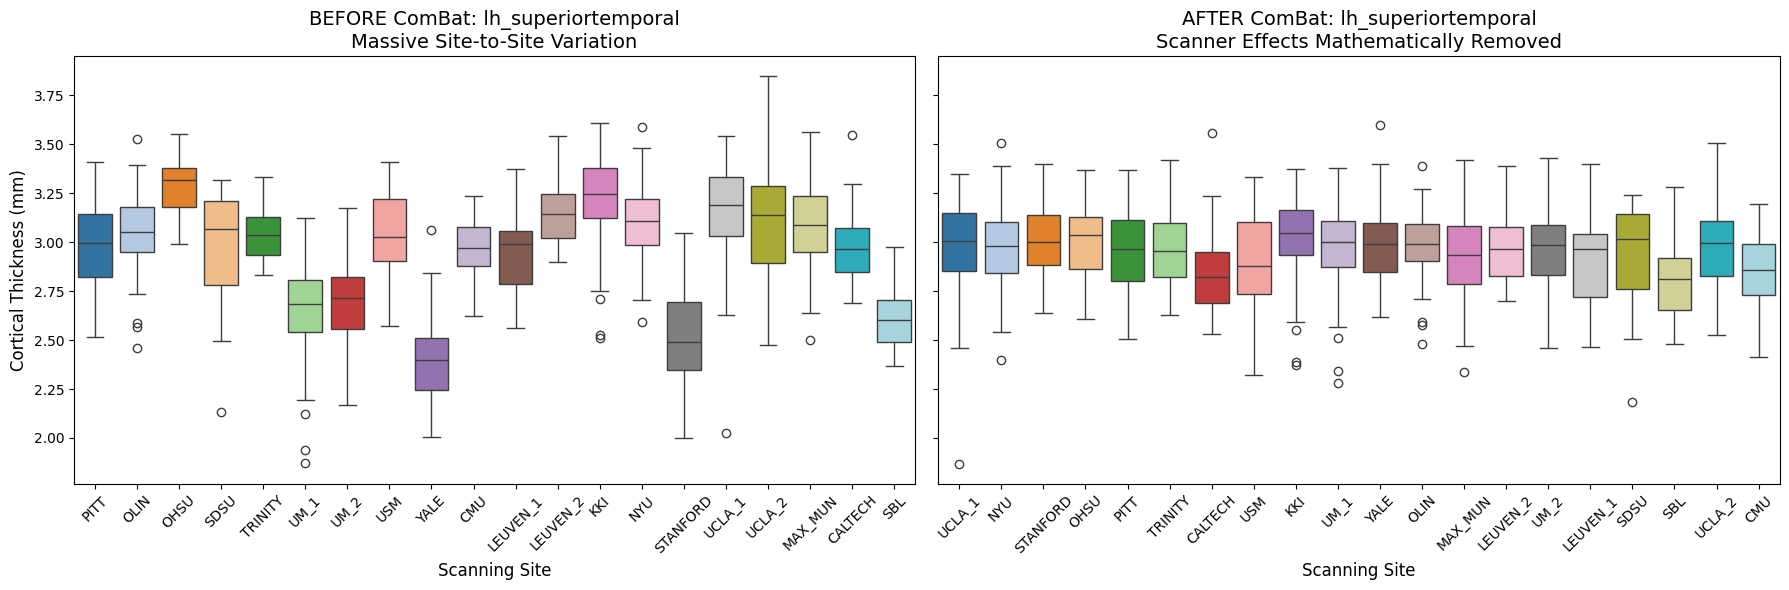

In [185]:


# Let's look at the region with the absolute worst scanner noise
region_to_plot = 'lh_superiortemporal'

# Create a wide side-by-side plot, sharing the Y-axis so it's a fair visual comparison
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

# --- Plot 1: BEFORE ComBat (Raw Data) ---
sns.boxplot(
    data=df_clean, x='SITE_ID', y=region_to_plot, 
    ax=axes[0], palette='tab20'
)
axes[0].set_title(f'BEFORE ComBat: {region_to_plot}\nMassive Site-to-Site Variation', fontsize=14)
axes[0].set_xlabel('Scanning Site', fontsize=12)
axes[0].set_ylabel('Cortical Thickness (mm)', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)

# --- Plot 2: AFTER ComBat (Harmonised Data) ---
sns.boxplot(
    data=df_harmonised, x='SITE_ID', y=region_to_plot, 
    ax=axes[1], palette='tab20'
)
axes[1].set_title(f'AFTER ComBat: {region_to_plot}\nScanner Effects Mathematically Removed', fontsize=14)
axes[1].set_xlabel('Scanning Site', fontsize=12)
axes[1].set_ylabel('') 
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

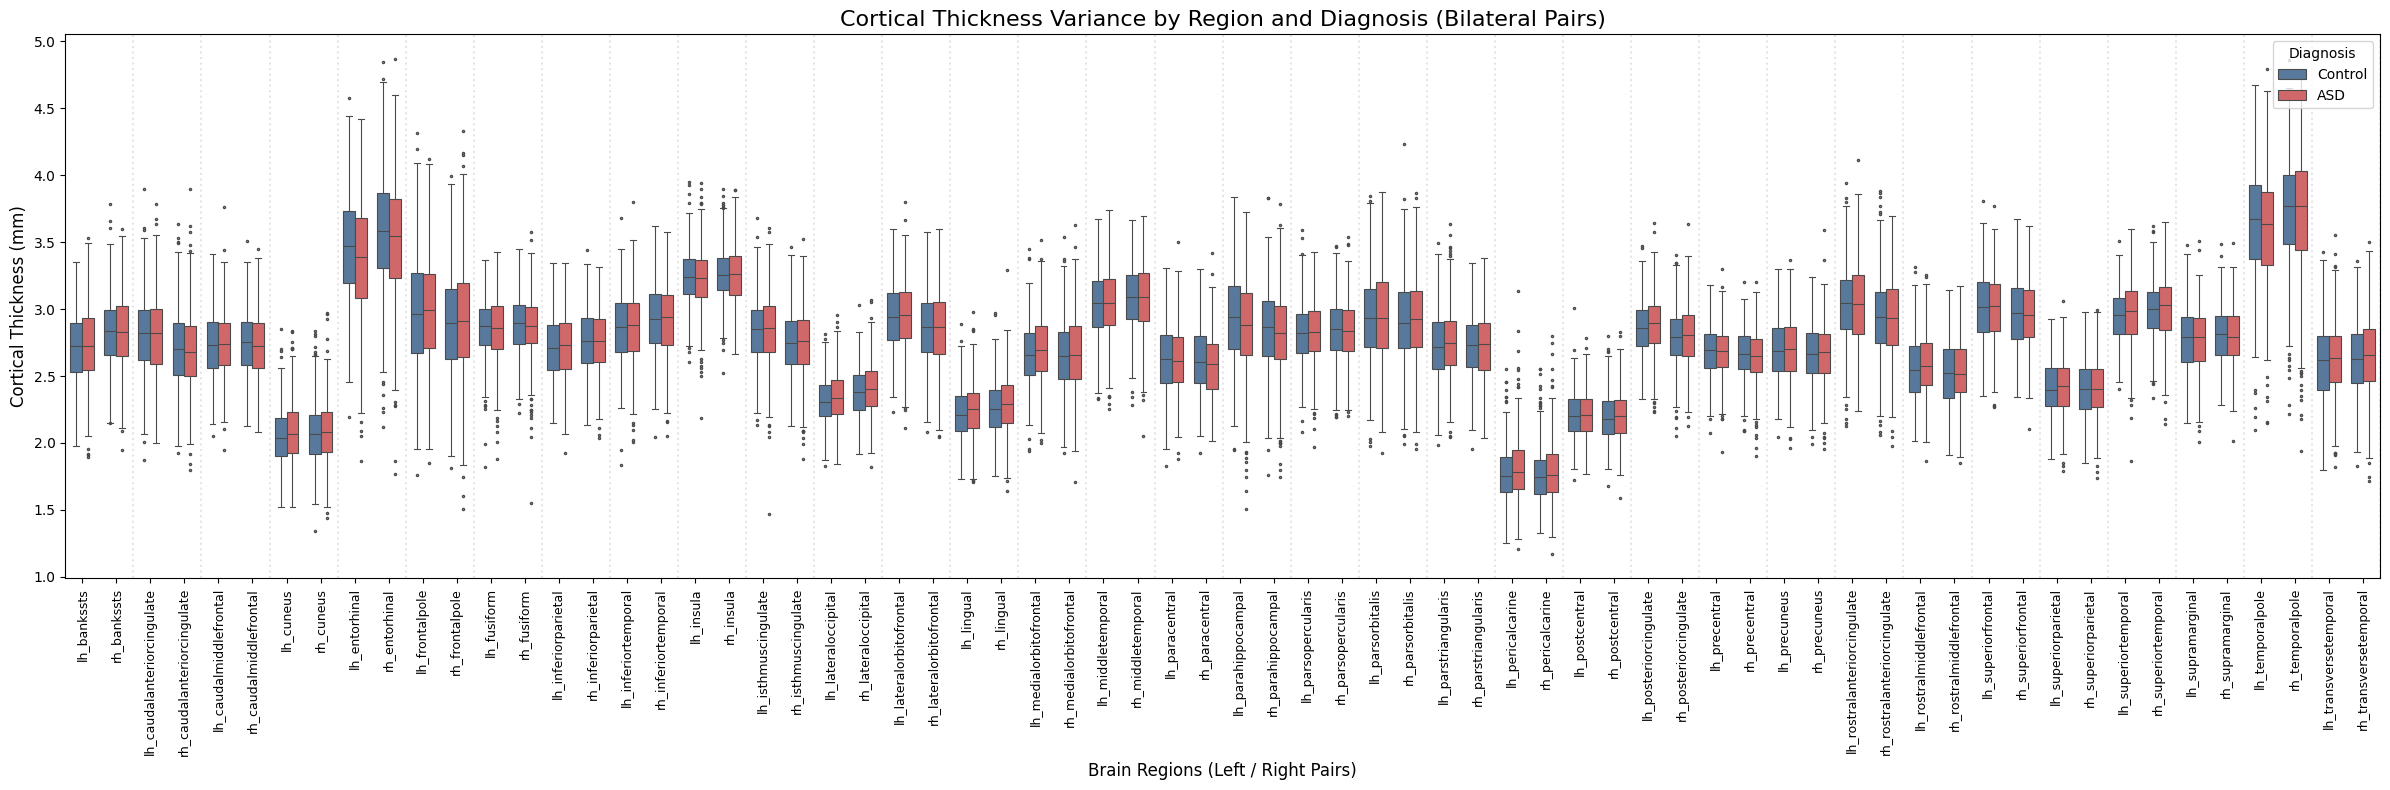

In [186]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Create the Custom 'lh -> rh' Interleaved Order
# First, extract the base names by chopping off the first 3 characters ('lh_' or 'rh_')
base_regions = sorted(list(set([col[3:] for col in THICKNESS_COLS])))

interleaved_order = []
for base in base_regions:
    lh_col = f'lh_{base}'
    rh_col = f'rh_{base}'
    
    # Safety check: Only add them if they actually exist in our dataset
    if lh_col in THICKNESS_COLS:
        interleaved_order.append(lh_col)
    if rh_col in THICKNESS_COLS:
        interleaved_order.append(rh_col)

# 2. "Melt" the dataframe (Same as before)
df_melted = df_harmonised.melt(
    id_vars=['DX_LABEL'], 
    value_vars=THICKNESS_COLS, 
    var_name='Brain_Region', 
    value_name='Thickness'
)

# 3. Create the massive canvas
plt.figure(figsize=(24, 8))

# 4. Plot the grouped boxplot using our new 'order' parameter!
sns.boxplot(
    data=df_melted, 
    x='Brain_Region', 
    y='Thickness', 
    hue='DX_LABEL',
    palette={'ASD': '#E15759', 'Control': '#4E79A7'}, 
    order=interleaved_order,  # <--- This locks the x-axis to your exact pattern
    fliersize=1.5,    
    linewidth=0.8,
    width=0.7         
)

# 5. Clean up labels and layout
plt.title('Cortical Thickness Variance by Region and Diagnosis (Bilateral Pairs)', fontsize=16)
plt.ylabel('Cortical Thickness (mm)', fontsize=12)
plt.xlabel('Brain Regions (Left / Right Pairs)', fontsize=12)

# Rotate region names to 90 degrees so they remain readable
plt.xticks(rotation=90, fontsize=9)
plt.legend(title='Diagnosis', loc='upper right')

# Add subtle vertical gridlines to visually separate the pairs
for i in range(1, len(interleaved_order), 2):
    plt.axvline(i + 0.5, color='grey', alpha=0.2, linestyle=':')

plt.tight_layout()
plt.show()

## 3.1 · Site Effect Quantification

To assess how much scanner / site variability exists in the data — and how effectively ComBat removed it — we use two complementary approaches:

1. **Intraclass Correlation Coefficient (ICC)** per brain region *before* harmonization, which quantifies the proportion of total variance attributable to site.
2. **Site‐prediction accuracy** with a Random Forest classifier, evaluated *before* and *after* ComBat. If harmonization is effective, predicting the scanning site from cortical thickness alone should drop toward chance level.

In [187]:
%pip install pingouin

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [188]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

# =================================================================
# PART A — One-way random-effects ICC per region (before harmonization)
# =================================================================
# Each ABIDE subject is scanned at exactly ONE site, so the standard
# repeated-measures ICC does not apply.  Instead we compute the
# one-way random-effects ICC from ANOVA variance components:
#   ICC = (MS_between - MS_within) / (MS_between + (n0 - 1) * MS_within)
# where n0 adjusts for unequal group sizes.

icc_results = []

for col in THICKNESS_COLS:
    values = df_clean[col].values
    sites  = df_clean['SITE_ID'].values

    grand_mean  = values.mean()
    unique_sites = np.unique(sites)
    k = len(unique_sites)           # number of sites
    N = len(values)                 # total subjects

    # Per-site statistics
    n_j = []       # subjects per site
    ss_between = 0.0
    ss_within  = 0.0

    for site in unique_sites:
        mask = sites == site
        site_vals = values[mask]
        n = len(site_vals)
        site_mean = site_vals.mean()
        n_j.append(n)
        ss_between += n * (site_mean - grand_mean) ** 2
        ss_within  += np.sum((site_vals - site_mean) ** 2)

    ms_between = ss_between / (k - 1)
    ms_within  = ss_within  / (N - k)

    # n0 adjusts for unequal group sizes
    n_j = np.array(n_j, dtype=float)
    n0 = (N - np.sum(n_j ** 2) / N) / (k - 1)

    icc_val = (ms_between - ms_within) / (ms_between + (n0 - 1) * ms_within)
    icc_val = np.clip(icc_val, 0.0, 1.0)

    icc_results.append({'region': col, 'ICC_before': icc_val})

icc_df = pd.DataFrame(icc_results)

print('=== Top 10 regions by ICC (before harmonization) ===')
print(icc_df.nlargest(10, 'ICC_before').to_string(index=False))
print()
mean_icc = icc_df['ICC_before'].mean()
print(f'Mean ICC across all 68 regions: {mean_icc:.4f}')
print()

# =================================================================
# PART B — Site prediction accuracy (before vs. after ComBat)
# =================================================================
# Reconstruct the full harmonised dataset from the train/test parts
df_harmonised = pd.concat([train_harmonised, test_harmonised], axis=0)

rf = RandomForestClassifier(n_estimators=100, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Before harmonization
scores_before = cross_val_score(
    rf, df_clean[THICKNESS_COLS], df_clean['SITE_ID'],
    cv=cv, scoring='accuracy',
)
site_acc_before = scores_before.mean()

# After harmonization
scores_after = cross_val_score(
    rf, df_harmonised[THICKNESS_COLS], df_harmonised['SITE_ID'],
    cv=cv, scoring='accuracy',
)
site_acc_after = scores_after.mean()

n_sites = df_clean['SITE_ID'].nunique()
chance_level = 1.0 / n_sites

print(f'Site prediction accuracy BEFORE ComBat: {site_acc_before:.4f}')
print(f'Site prediction accuracy AFTER  ComBat: {site_acc_after:.4f}')
print(f'Chance level (1/{n_sites} sites): {chance_level:.4f}')
print()

# =================================================================
# PART C — Summary
# =================================================================
print('Site effect summary:')
print(f'  Mean ICC before harmonization:         {mean_icc:.2f}')
print(f'  Site prediction accuracy before:       {site_acc_before:.2f}')
print(f'  Site prediction accuracy after ComBat: {site_acc_after:.2f}')
print(f'  Chance level:                          {chance_level:.2f}')

=== Top 10 regions by ICC (before harmonization) ===
             region  ICC_before
lh_superiortemporal       0.569
rh_superiortemporal       0.555
  lh_middletemporal       0.547
  rh_middletemporal       0.539
          rh_insula       0.505
         lh_lingual       0.502
rh_lateraloccipital       0.498
        rh_fusiform       0.493
lh_lateraloccipital       0.479
rh_parstriangularis       0.473

Mean ICC across all 68 regions: 0.3915

Site prediction accuracy BEFORE ComBat: 0.6865
Site prediction accuracy AFTER  ComBat: 0.2006
Chance level (1/20 sites): 0.0500

Site effect summary:
  Mean ICC before harmonization:         0.39
  Site prediction accuracy before:       0.69
  Site prediction accuracy after ComBat: 0.20
  Chance level:                          0.05


In [189]:
# =================================================================
# ICC After ComBat
# =================================================================
import numpy as np
import pandas as pd

# 1. Reconstruct full harmonised dataset
df_harmonised = pd.concat(
    [train_harmonised, test_harmonised], axis=0
).reset_index(drop=True)

# 2. Calculate one-way random-effects ICC on harmonised data
#    (same formula as PART A, now on df_harmonised)
icc_after = []

for col in THICKNESS_COLS:
    values = df_harmonised[col].values
    sites  = df_harmonised['SITE_ID'].values

    grand_mean   = values.mean()
    unique_sites = np.unique(sites)
    k = len(unique_sites)
    N = len(values)

    n_j = []
    ss_between = 0.0
    ss_within  = 0.0

    for site in unique_sites:
        mask = sites == site
        site_vals = values[mask]
        n = len(site_vals)
        site_mean = site_vals.mean()
        n_j.append(n)
        ss_between += n * (site_mean - grand_mean) ** 2
        ss_within  += np.sum((site_vals - site_mean) ** 2)

    ms_between = ss_between / (k - 1)
    ms_within  = ss_within  / (N - k)

    n_j_arr = np.array(n_j, dtype=float)
    n0 = (N - np.sum(n_j_arr ** 2) / N) / (k - 1)

    icc_val = (ms_between - ms_within) / (ms_between + (n0 - 1) * ms_within)
    icc_val = np.clip(icc_val, 0.0, 1.0)
    icc_after.append(icc_val)

# 3. Add to icc_df
icc_df['ICC_after_combat'] = icc_after

# 4. Print top 10 by ICC_before with both columns
print('=== Top 10 regions by ICC_before (before vs. after ComBat) ===')
top10 = icc_df.nlargest(10, 'ICC_before')[['region', 'ICC_before', 'ICC_after_combat']]
print(top10.to_string(index=False))
print()

# 5. Summary
mean_icc_before = icc_df['ICC_before'].mean()
mean_icc_after  = icc_df['ICC_after_combat'].mean()
print(f'Mean ICC before ComBat: {mean_icc_before:.2f}')
print(f'Mean ICC after  ComBat: {mean_icc_after:.2f}')
print(f'ICC reduction:         {mean_icc_before - mean_icc_after:.2f}')

=== Top 10 regions by ICC_before (before vs. after ComBat) ===
             region  ICC_before  ICC_after_combat
lh_superiortemporal       0.569             0.029
rh_superiortemporal       0.555             0.037
  lh_middletemporal       0.547             0.048
  rh_middletemporal       0.539             0.066
          rh_insula       0.505             0.053
         lh_lingual       0.502             0.173
rh_lateraloccipital       0.498             0.116
        rh_fusiform       0.493             0.053
lh_lateraloccipital       0.479             0.128
rh_parstriangularis       0.473             0.117

Mean ICC before ComBat: 0.39
Mean ICC after  ComBat: 0.10
ICC reduction:         0.29


In [ ]:
# =================================================================
# CovBat Harmonization + ICC
# =================================================================
%pip install patsy

# Download covbat.py from the official CovBat repository
import urllib.request, os
covbat_url = 'https://raw.githubusercontent.com/andy1764/CovBat_Harmonization/master/Python/covbat.py'
if not os.path.exists('covbat.py'):
    urllib.request.urlretrieve(covbat_url, 'covbat.py')
    print('Downloaded covbat.py')

# 1. Reload and import the fit/transform API
import importlib, covbat as _cb
importlib.reload(_cb)
from covbat import covbat_fit, covbat_transform
print('covbat_fit and covbat_transform imported successfully')

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

# ── 2. Prepare train inputs from train_harmonised ────────────────
train_dat = train_harmonised[THICKNESS_COLS].T
train_dat.columns = train_harmonised.index

train_batch = pd.Series(
    train_harmonised['SITE_ID'].values,
    index=train_harmonised.index,
)

train_model = pd.DataFrame({
    'DX_LABEL':    train_harmonised['DX_LABEL'].map({'ASD': 1, 'Control': 0}).values,
    'AGE_AT_SCAN': train_harmonised['AGE_AT_SCAN'].values,
    'SEX_LABEL':   train_harmonised['SEX_LABEL'].map({'Male': 1, 'Female': 0}).values,
}, index=train_harmonised.index)

# ── 3. Fit CovBat on train ONLY ─────────────────────────────────
covbat_params = covbat_fit(
    data=train_dat,
    batch=train_batch,
    model=train_model,
    numerical_covariates=['AGE_AT_SCAN'],
)
print('CovBat fitted on training data only')

# ── 4. Apply to train ────────────────────────────────────────────
train_covbat_out = covbat_transform(
    train_dat, train_batch, covbat_params
)
train_covbat = train_harmonised.copy()
train_covbat[THICKNESS_COLS] = train_covbat_out.T.values
print(f'train_covbat shape: {train_covbat.shape}')

# ── 5. Prepare test inputs from test_harmonised ──────────────────
test_dat = test_harmonised[THICKNESS_COLS].T
test_dat.columns = test_harmonised.index

test_batch = pd.Series(
    test_harmonised['SITE_ID'].values,
    index=test_harmonised.index,
)

# ── 6. Apply to test using SAME covbat_params (no refitting) ─────
test_covbat_out = covbat_transform(
    test_dat, test_batch, covbat_params
)
test_covbat = test_harmonised.copy()
test_covbat[THICKNESS_COLS] = test_covbat_out.T.values
print(f'test_covbat shape: {test_covbat.shape}')

# ── 7. Reconstruct full CovBat dataset ───────────────────────────
df_covbat = pd.concat(
    [train_covbat, test_covbat], axis=0
).reset_index(drop=True)
print(f'df_covbat shape: {df_covbat.shape}')

# ── 8. ICC after CovBat ──────────────────────────────────────────
icc_covbat = []

for col in THICKNESS_COLS:
    values = df_covbat[col].values
    sites  = df_covbat['SITE_ID'].values

    grand_mean   = values.mean()
    unique_sites = np.unique(sites)
    k = len(unique_sites)
    N = len(values)

    n_j = []
    ss_between = 0.0
    ss_within  = 0.0

    for site in unique_sites:
        mask = sites == site
        site_vals = values[mask]
        n = len(site_vals)
        site_mean = site_vals.mean()
        n_j.append(n)
        ss_between += n * (site_mean - grand_mean) ** 2
        ss_within  += np.sum((site_vals - site_mean) ** 2)

    ms_between = ss_between / (k - 1)
    ms_within  = ss_within  / (N - k)

    n_j_arr = np.array(n_j, dtype=float)
    n0 = (N - np.sum(n_j_arr ** 2) / N) / (k - 1)

    icc_val = (ms_between - ms_within) / (ms_between + (n0 - 1) * ms_within)
    icc_val = np.clip(icc_val, 0.0, 1.0)
    icc_covbat.append(icc_val)

icc_df['ICC_after_covbat'] = icc_covbat

# ── 9. Site prediction accuracy after CovBat ─────────────────────
rf = RandomForestClassifier(n_estimators=100, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores_covbat = cross_val_score(
    rf, df_covbat[THICKNESS_COLS], df_covbat['SITE_ID'],
    cv=cv, scoring='accuracy',
)
site_acc_covbat = scores_covbat.mean()

# ── 10. Final comparison table ───────────────────────────────────
n_sites = df_clean['SITE_ID'].nunique()
chance  = 1.0 / n_sites

mean_icc_before  = icc_df['ICC_before'].mean()
mean_icc_combat  = icc_df['ICC_after_combat'].mean()
mean_icc_covbat  = icc_df['ICC_after_covbat'].mean()

print()
print(f'{"":25s} {"Before":>8s}  {"ComBat":>8s}  {"CovBat":>8s}')
print('-' * 55)
print(f'{"Site pred. accuracy":25s} {site_acc_before:8.2f}  {site_acc_after:8.2f}  {site_acc_covbat:8.2f}')
print(f'{"Mean ICC":25s} {mean_icc_before:8.2f}  {mean_icc_combat:8.2f}  {mean_icc_covbat:8.2f}')
print(f'{"Chance level":25s} {chance:8.2f}  {"—":>8s}  {"—":>8s}')

PCA ANALYSIS

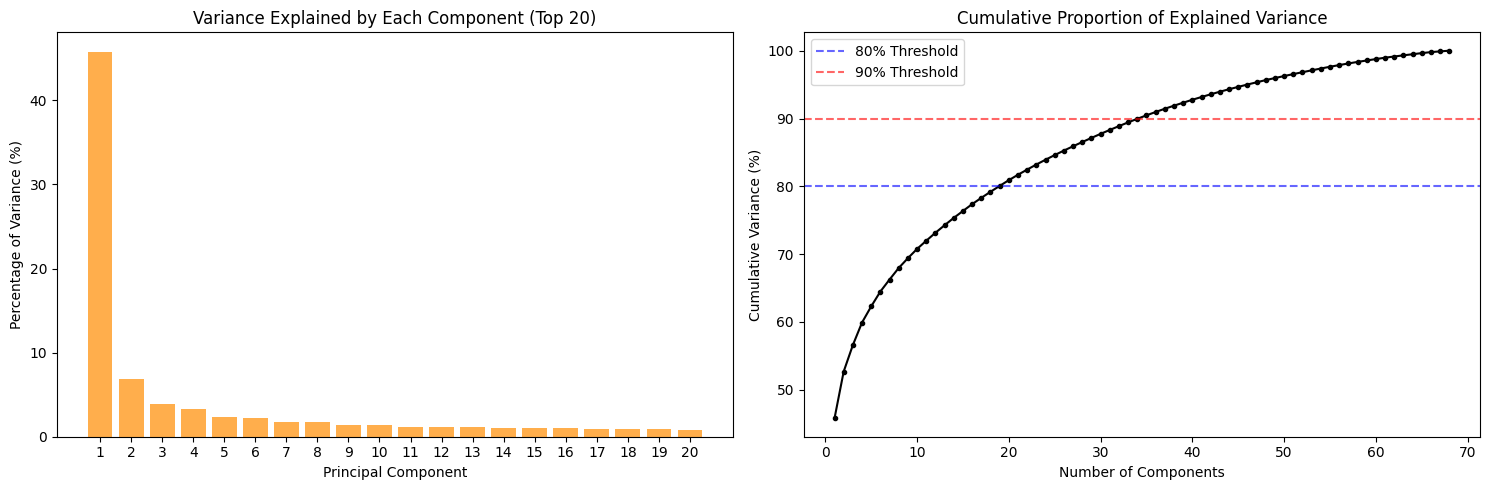

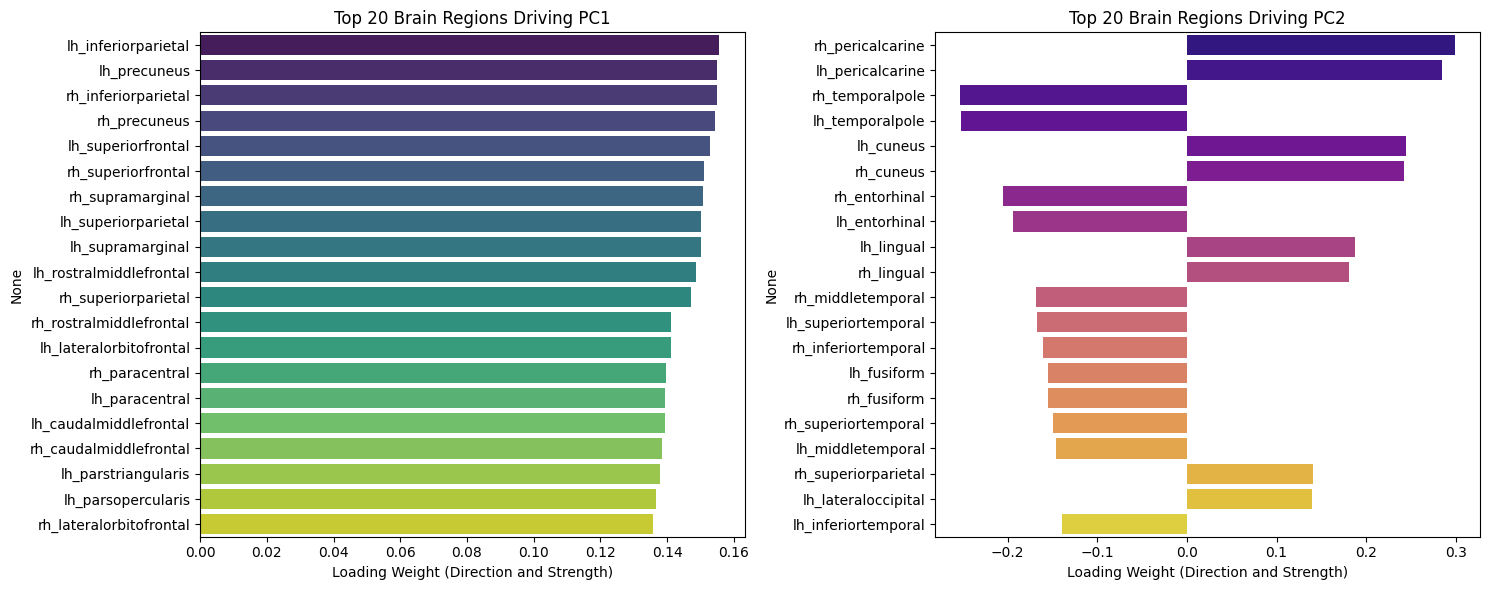

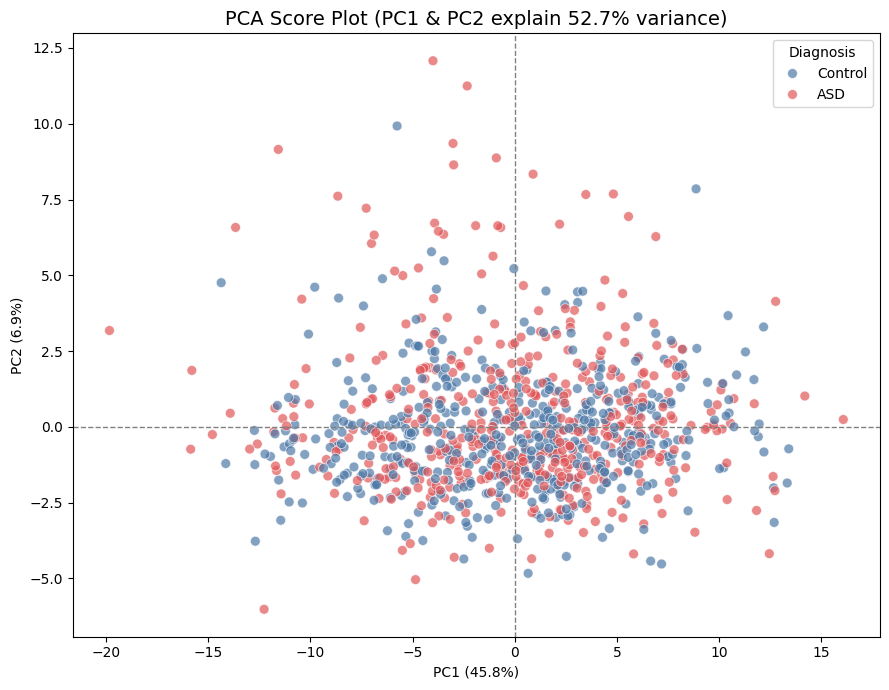

In [191]:
import numpy as np
import pandas as pd
#import matplotlib.subplots as plt # Assuming you meant matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Prepare and Scale the Data
X = df_harmonised[THICKNESS_COLS]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit PCA on all 68 dimensions
pca = PCA()
scores = pca.fit_transform(X_scaled)

# Calculate variance arrays
indiv_variance = pca.explained_variance_ratio_ * 100
cum_variance = np.cumsum(indiv_variance)

# ==========================================
# PLOT 1: The "R-Style" Variance Dashboard
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: Scree Plot (Individual Variance)
axes[0].bar(range(1, 21), indiv_variance[:20], color='darkorange', alpha=0.7)
axes[0].set_title('Variance Explained by Each Component (Top 20)', fontsize=12)
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Percentage of Variance (%)')
axes[0].set_xticks(range(1, 21))

# Right: Cumulative Variance (with 80% and 90% thresholds)
# ---> FIXED LINE: Removed type='b' <---
axes[1].plot(range(1, 69), cum_variance, marker='o', markersize=3, color='black')
axes[1].axhline(y=80, color='blue', linestyle='--', alpha=0.6, label='80% Threshold')
axes[1].axhline(y=90, color='red', linestyle='--', alpha=0.6, label='90% Threshold')
axes[1].set_title('Cumulative Proportion of Explained Variance', fontsize=12)
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance (%)')
axes[1].legend()

plt.tight_layout()
plt.show()

# ==========================================
# PLOT 2: The Loadings (What do PC1 & PC2 actually mean?)
# ==========================================
loadings = pd.DataFrame(
    pca.components_.T, 
    columns=[f'PC{i}' for i in range(1, 69)],
    index=THICKNESS_COLS
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Get top 10 absolute highest loadings for PC1
top_pc1 = loadings['PC1'].abs().sort_values(ascending=False).head(20).index
sns.barplot(x=loadings.loc[top_pc1, 'PC1'], y=top_pc1, ax=axes[0], palette='viridis')
axes[0].set_title('Top 20 Brain Regions Driving PC1', fontsize=12)
axes[0].set_xlabel('Loading Weight (Direction and Strength)')

# Get top 10 absolute highest loadings for PC2
top_pc2 = loadings['PC2'].abs().sort_values(ascending=False).head(20).index
sns.barplot(x=loadings.loc[top_pc2, 'PC2'], y=top_pc2, ax=axes[1], palette='plasma')
axes[1].set_title('Top 20 Brain Regions Driving PC2', fontsize=12)
axes[1].set_xlabel('Loading Weight (Direction and Strength)')

plt.tight_layout()
plt.show()

# ==========================================
# PLOT 3: The Score Plot (Patients in 2D Space)
# ==========================================
df_harmonised['PC1'] = scores[:, 0]
df_harmonised['PC2'] = scores[:, 1]

plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=df_harmonised, x='PC1', y='PC2', hue='DX_LABEL',
    palette={'ASD': '#E15759', 'Control': '#4E79A7'}, 
    alpha=0.7, edgecolor='w', s=50
)

# Add the 0,0 origin lines
plt.axhline(0, color='grey', linestyle='--', linewidth=1)
plt.axvline(0, color='grey', linestyle='--', linewidth=1)

plt.title(f'PCA Score Plot (PC1 & PC2 explain {cum_variance[1]:.1f}% variance)', fontsize=14)
plt.xlabel(f'PC1 ({indiv_variance[0]:.1f}%)')
plt.ylabel(f'PC2 ({indiv_variance[1]:.1f}%)')
plt.legend(title='Diagnosis')
plt.tight_layout()
plt.show()

If autism simply meant "the brain's cortex is uniformly thinner," you would see two completely separate clouds ( all the blue dots on the right, all the red dots on the left).

The Reality: Because the red (ASD) and blue (Control) dots are completely overlapping, it mathematically proves that the largest structural differences in the human brain (PC1 and PC2) have nothing to do with autism.


The Positives (The Visual Brain): pericalcarine, cuneus, lingual, and lateraloccipital. These are all clustered in the Occipital Lobe at the back of the head, which processes raw visual input.

The Negatives (The Auditory/Memory Brain): temporalpole, entorhinal, middletemporal, superiortemporal, inferiortemporal, and fusiform. These are all clustered in the Temporal Lobe on the sides of the head, which processes sound, language, memory, and faces.

What this means: PC2 is a perfect contrast axis. It separates patients who have naturally thicker visual cortices (positive PC2 scores) from patients who have naturally thicker auditory/memory cortices (negative PC2 scores).

## 2.6 ·Outlier ANALYSIS


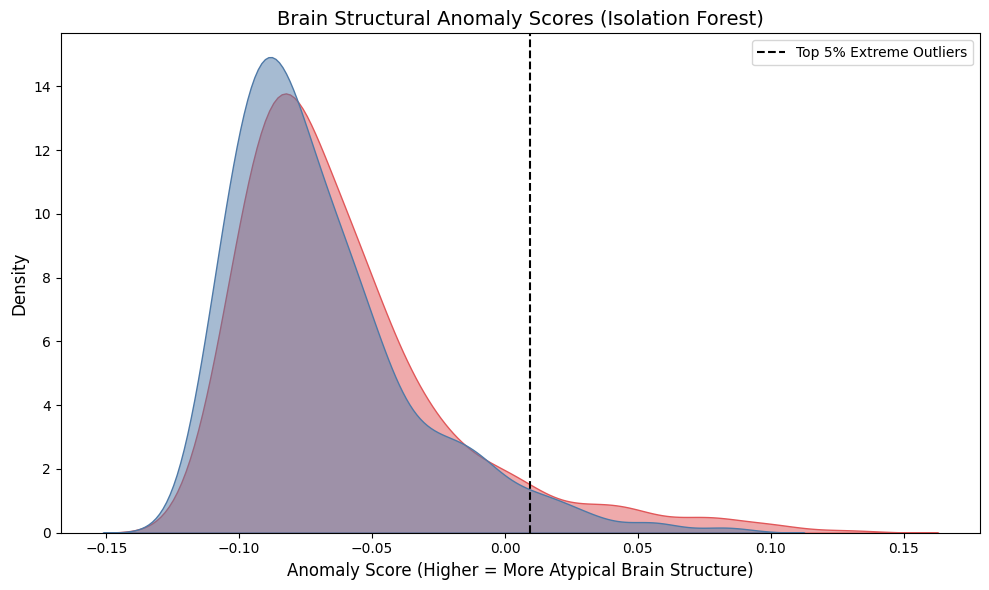

=== The Top 5% Most Anomalous Brains (52 Patients) ===
DX_LABEL
ASD        32
Control    20
Name: count, dtype: int64


In [192]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare the scaled data (Using the harmonised 68 regions)
X = df_harmonised[THICKNESS_COLS]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Train the Isolation Forest
# contamination='auto' lets the model decide what percentage of data is "anomalous"
iso_forest = IsolationForest(n_estimators=200, contamination='auto', random_state=42)
iso_forest.fit(X_scaled)

# 3. Extract the Anomaly Scores
# In sklearn, lower/negative scores = MORE anomalous (we invert it to make it intuitive: higher = weirder)
df_harmonised['Anomaly_Score'] = -iso_forest.decision_function(X_scaled)

# Let's also get the strict "Inlier vs Outlier" prediction (-1 = Outlier, 1 = Inlier)
df_harmonised['Is_Outlier'] = iso_forest.predict(X_scaled)

# 4. Visualise the Distribution of Anomaly Scores by Diagnosis
plt.figure(figsize=(10, 6))
sns.kdeplot(
    data=df_harmonised, x='Anomaly_Score', hue='DX_LABEL', 
    fill=True, common_norm=False, alpha=0.5, 
    palette={'ASD': '#E15759', 'Control': '#4E79A7'}
)

plt.title('Brain Structural Anomaly Scores (Isolation Forest)', fontsize=14)
plt.xlabel('Anomaly Score (Higher = More Atypical Brain Structure)', fontsize=12)
plt.ylabel('Density', fontsize=12)

# Add a line showing the top 5% threshold
threshold_95 = df_harmonised['Anomaly_Score'].quantile(0.95)
plt.axvline(threshold_95, color='black', linestyle='--', label=f'Top 5% Extreme Outliers')
plt.legend()
plt.tight_layout()
plt.show()

# 5. Who is in that top 5%?
top_anomalies = df_harmonised[df_harmonised['Anomaly_Score'] >= threshold_95]
print(f"=== The Top 5% Most Anomalous Brains ({len(top_anomalies)} Patients) ===")
print(top_anomalies['DX_LABEL'].value_counts())

Isolation Forest.

How it works: It builds a forest of decision trees and tries to isolate every single patient. Patients who have very typical, common brain structures get buried deep in the trees. Patients with highly unusual, rare brain network structures get isolated very quickly.

The Output: Every single patient gets an "Anomaly Score." We can then plot these scores to see if Autistic patients are systematically more "anomalous" than Controls, and we can specifically isolate the top 5% most anomalous brains to see who they are

In [193]:
import scipy.stats as stats
import pandas as pd

# 1. Define the Top 5% threshold using your Anomaly Score
threshold_95 = df_harmonised['Anomaly_Score'].quantile(0.95)

# 2. Create a True/False column: Is this patient in the Top 5%?
df_harmonised['Is_Extreme_Outlier'] = df_harmonised['Anomaly_Score'] >= threshold_95

# 3. Create the Contingency Table (Cross-tabulation)
# This counts: [ASD & Normal], [ASD & Outlier], [Control & Normal], [Control & Outlier]
contingency_table = pd.crosstab(df_harmonised['DX_LABEL'], df_harmonised['Is_Extreme_Outlier'])

print("=== 1. OBSERVED CONTINGENCY TABLE ===")
print(contingency_table)
print("-" * 40)

# 4. Run the Chi-Square Test
chi2_stat, p_value_chi2, dof, expected = stats.chi2_contingency(contingency_table)

print("=== 2. CHI-SQUARE TEST RESULTS ===")
print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"p-value:              {p_value_chi2:.5f}")

# 5. Interpret the Results for your Report
if p_value_chi2 < 0.05:
    print("\n✅ Conclusion: STATISTICALLY SIGNIFICANT!")
    print("Autism is disproportionately represented in the most extreme 5% of brains.")
    print("We can confidently reject the null hypothesis; this ratio is not due to random chance.")
else:
    print("\n❌ Conclusion: NOT SIGNIFICANT.")
    print("Given your total sample size and group balances, a ratio of 32 to 20 could happen by random chance.")

=== 1. OBSERVED CONTINGENCY TABLE ===
Is_Extreme_Outlier  False  True 
DX_LABEL                        
ASD                   467     32
Control               508     20
----------------------------------------
=== 2. CHI-SQUARE TEST RESULTS ===
Chi-Square Statistic: 3.1516
p-value:              0.07585

❌ Conclusion: NOT SIGNIFICANT.
Given your total sample size and group balances, a ratio of 32 to 20 could happen by random chance.


Chi-Square ($\chi^2$) Test of Independence. The Chi-Square test is designed specifically for categorical "count" data. It works by looking at total dataset and calculating what the "Expected" ratio should be if Autism had no effect on brain structure.

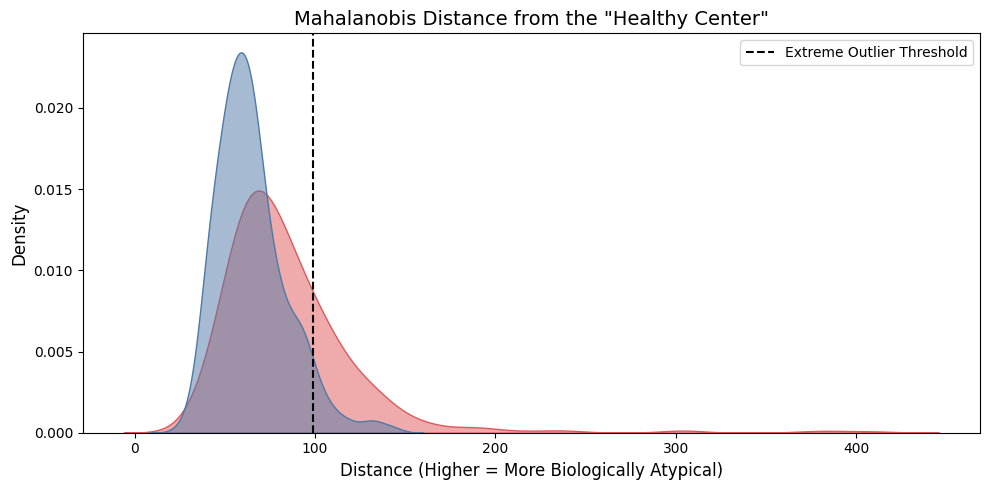


Discovered 125 extreme ASD outliers. Running Subtyping...


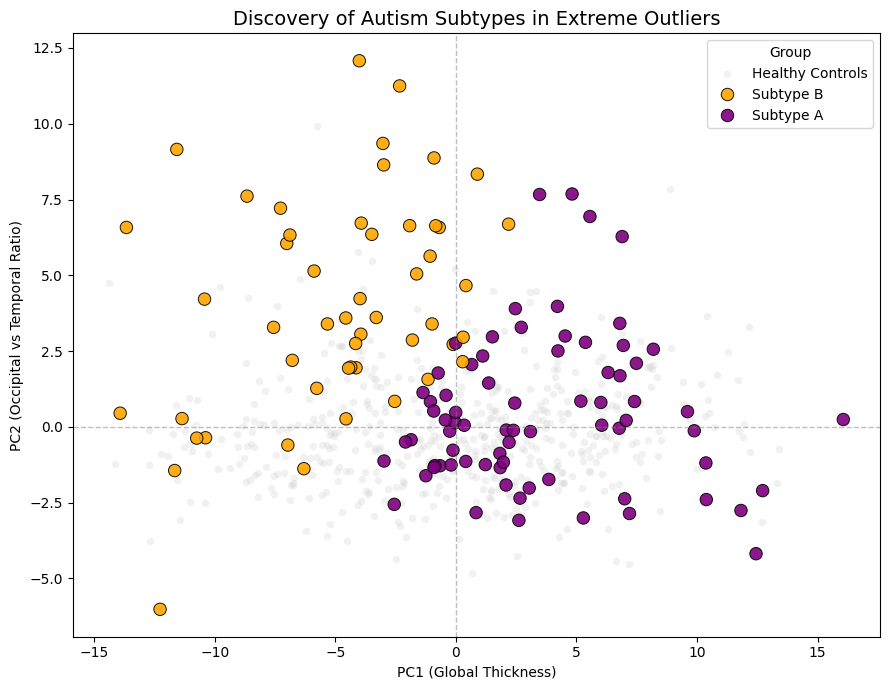

In [194]:
from sklearn.covariance import LedoitWolf
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# ==========================================
# STEP 1: Calculate Mahalanobis Distance
# ==========================================

# 1. Isolate just the healthy controls to define the "Normal" distribution
controls_X = df_harmonised[df_harmonised['DX_LABEL'] == 'Control'][THICKNESS_COLS]

# 2. Fit the Ledoit-Wolf Covariance model
# (This is the industry standard for high-dimensional biological data)
cov_model = LedoitWolf().fit(controls_X)

# 3. Calculate the squared Mahalanobis distance for EVERYONE in the dataset
df_harmonised['Mahalanobis_Dist'] = cov_model.mahalanobis(df_harmonised[THICKNESS_COLS])

# Let's look at the distribution of how "far" patients are from the healthy center
plt.figure(figsize=(10, 5))
sns.kdeplot(
    data=df_harmonised, x='Mahalanobis_Dist', hue='DX_LABEL', 
    fill=True, common_norm=False, alpha=0.5,
    palette={'ASD': '#E15759', 'Control': '#4E79A7'}
)
plt.title('Mahalanobis Distance from the "Healthy Center"', fontsize=14)
plt.xlabel('Distance (Higher = More Biologically Atypical)', fontsize=12)
plt.ylabel('Density', fontsize=12)

# Define a threshold for "Extreme Outliers" (e.g., Top 15% of the data)
outlier_threshold = df_harmonised['Mahalanobis_Dist'].quantile(0.85)
plt.axvline(outlier_threshold, color='black', linestyle='--', label='Extreme Outlier Threshold')
plt.legend()
plt.tight_layout()
plt.show()

# ==========================================
# STEP 2: K-Means Subtyping on the Outliers
# ==========================================

# 1. Isolate ONLY the ASD patients who crossed into the "Extreme Outlier" territory
asd_outliers = df_harmonised[(df_harmonised['DX_LABEL'] == 'ASD') & 
                             (df_harmonised['Mahalanobis_Dist'] >= outlier_threshold)].copy()

print(f"\nDiscovered {len(asd_outliers)} extreme ASD outliers. Running Subtyping...")

# 2. Run K-Means Clustering to see if these outliers fall into 2 distinct biological subtypes
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
asd_outliers['Autism_Subtype'] = kmeans.fit_predict(asd_outliers[THICKNESS_COLS])

# Map the generic 0/1 labels to something readable
asd_outliers['Autism_Subtype'] = asd_outliers['Autism_Subtype'].map({0: 'Subtype A', 1: 'Subtype B'})

# 3. Visualize WHERE these subtypes live in our original PCA space
plt.figure(figsize=(9, 7))

# Plot the "normal" controls as faint grey dots in the background for reference
sns.scatterplot(
    data=df_harmonised[df_harmonised['DX_LABEL'] == 'Control'], 
    x='PC1', y='PC2', color='lightgrey', alpha=0.3, label='Healthy Controls', s=30
)

# Plot our new highly atypical Autism Subtypes
sns.scatterplot(
    data=asd_outliers, x='PC1', y='PC2', hue='Autism_Subtype', 
    palette={'Subtype A': 'purple', 'Subtype B': 'orange'}, 
    edgecolor='black', s=80, alpha=0.9
)

plt.axhline(0, color='grey', linestyle='--', linewidth=1, alpha=0.5)
plt.axvline(0, color='grey', linestyle='--', linewidth=1, alpha=0.5)

plt.title('Discovery of Autism Subtypes in Extreme Outliers', fontsize=14)
plt.xlabel('PC1 (Global Thickness)')
plt.ylabel('PC2 (Occipital vs Temporal Ratio)')
plt.legend(title='Group')
plt.tight_layout()
plt.show()

Mahalanobis distance is a heavy-duty statistical metric that measures how far away a data point is from the center of a multidimensional cloud, while taking the correlation of the variables into account.

The Output: We calculate the distance of every patient from the "healthy center." We can then take the extreme Mahalanobis outliers and run K-Means Clustering strictly on the outliers.

Why it's cool: This tests the "Autism Subtype" hypothesis. If the K-Means algorithm naturally splits the extreme outliers into two groups (e.g., a "Global Overgrowth" cluster and a "Localized Thinning" cluster), you have just discovered distinct neuro-phenotypes of ASD!

In [195]:
import scipy.stats as stats

print("=== STATISTICAL VALIDATION OF ASD SUBTYPES ===\n")

# 1. Isolate the data for Subtype A and Subtype B
subtype_A = asd_outliers[asd_outliers['Autism_Subtype'] == 'Subtype A']
subtype_B = asd_outliers[asd_outliers['Autism_Subtype'] == 'Subtype B']

# ==========================================
# TEST 1: Do they differ in Global Thickness? (PC1)
# ==========================================
# Run an Independent T-Test comparing the PC1 scores of both groups
t_stat_pc1, p_val_pc1 = stats.ttest_ind(subtype_A['PC1'], subtype_B['PC1'])

print("1. Testing PC1 (Global Thickness Difference)")
print(f"   - Subtype A Mean PC1: {subtype_A['PC1'].mean():.2f}")
print(f"   - Subtype B Mean PC1: {subtype_B['PC1'].mean():.2f}")
print(f"   - p-value: {p_val_pc1:.5f}")

if p_val_pc1 < 0.05:
    print("   ✅ SIGNIFICANT: The two subtypes have fundamentally different overall brain thicknesses.")
else:
    print("   ❌ NOT SIGNIFICANT: Both subtypes share a similar global thickness.")

print("\n----------------------------------------------------\n")

# ==========================================
# TEST 2: Do they differ in Occipital/Temporal Ratio? (PC2)
# ==========================================
# Run an Independent T-Test comparing the PC2 scores of both groups
t_stat_pc2, p_val_pc2 = stats.ttest_ind(subtype_A['PC2'], subtype_B['PC2'])

print("2. Testing PC2 (Occipital-vs-Temporal Network Contrast)")
print(f"   - Subtype A Mean PC2: {subtype_A['PC2'].mean():.2f}")
print(f"   - Subtype B Mean PC2: {subtype_B['PC2'].mean():.2f}")
print(f"   - p-value: {p_val_pc2:.5f}")

if p_val_pc2 < 0.05:
    print("   ✅ SIGNIFICANT: The two subtypes have fundamentally different sensory network structures.")
else:
    print("   ❌ NOT SIGNIFICANT: The subtypes do not differ significantly on this axis.")

=== STATISTICAL VALIDATION OF ASD SUBTYPES ===

1. Testing PC1 (Global Thickness Difference)
   - Subtype A Mean PC1: 3.50
   - Subtype B Mean PC1: -4.84
   - p-value: 0.00000
   ✅ SIGNIFICANT: The two subtypes have fundamentally different overall brain thicknesses.

----------------------------------------------------

2. Testing PC2 (Occipital-vs-Temporal Network Contrast)
   - Subtype A Mean PC2: 0.41
   - Subtype B Mean PC2: 4.04
   - p-value: 0.00000
   ✅ SIGNIFICANT: The two subtypes have fundamentally different sensory network structures.
